# 01 - Exploratory Data Analysis & Data Pipeline

**Owner:** Shubham Behri

### Objectives:
- Load raw space-separated german.data with correct column headers and no data loss.
- Recode the target variable so that BAD = 1 (positive class) and GOOD = 0 (negative class).
- Verify special category encodings (e.g. A65 unknown savings, A124 no property) as distinct categories rather than missing data.
- Explore univariate numerical distributions, categorical proportions, and bivariate relationships with credit risk.
- Provide written domain interpretations and lay the foundation for preprocessing and feature engineering.



## Section 1: Data Ingestion & Schema Verification


### Interpretation

*Write your interpretation here.*


In [1]:
import pandas as pd
import numpy as np

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

# Define column names
column_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_duration",
    "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "people_liable",
    "telephone", "foreign_worker", "credit_risk"
]

# Load raw dataset
df = pd.read_csv(url, sep=r"\s+", header=None, names=column_names)

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Data type verification
print("\nData Types:")
print(df.dtypes)

# Schema verification
assert df.shape == (1000, 21), "Incorrect dataset dimensions!"
assert df.columns.tolist() == column_names, "Column names mismatch!"

print("\nSECTION 1 COMPLETED SUCCESSFULLY!")
print("1000 Records | 21 Columns | Schema Verified")

Dataset Shape: (1000, 21)

First Five Records:


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Column Names:
['checking_account', 'duration_months', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_account         1000 non-null   str  
 1   duration_months          1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_account          1000 non-null   str  
 6   employment_duration      1000 non-null   str  
 7   installment_rate         1000 non-null   

## Section 2: Target Variable Distribution & Recoding (BAD=1, GOOD=0)


### Interpretation

*Write your interpretation here.*


Original Target Distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64

Recoded Target Distribution:
risk_label
GOOD    700
BAD     300
Name: count, dtype: int64

Target Class Summary:


,Credit_Category,Encoded_Value,Customer_Count,Percentage
0,GOOD,0,700,70.0
1,BAD,1,300,30.0



Positive Class (BAD): 300
Negative Class (GOOD): 700


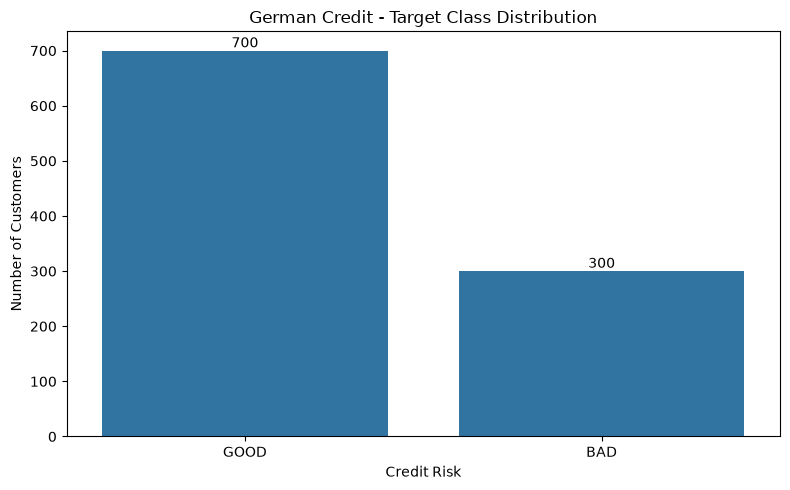

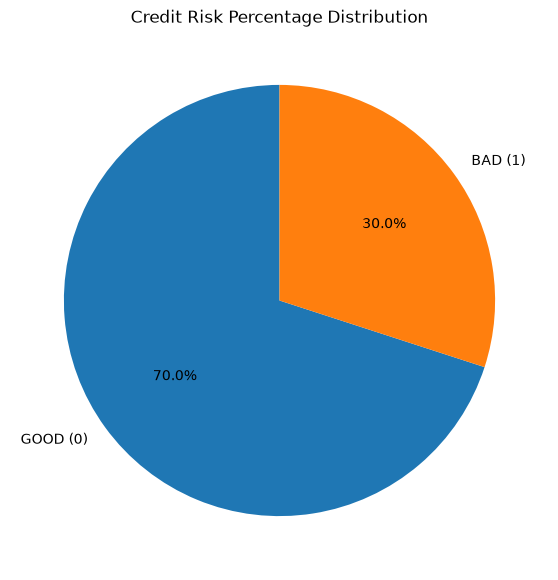


Class Imbalance Ratio: 2.33
The dataset has class imbalance.

Target Encoding Verified Successfully!

DOMAIN INTERPRETATION
---------------------------------------
1. GOOD credit customers represent 70% of the dataset.
2. BAD credit customers represent 30% of the dataset.
3. BAD credit (1) is the positive class.
4. GOOD credit (0) is the negative class.
5. The dataset has a 70:30 class distribution.
6. Accuracy alone may not be sufficient for model evaluation.
7. Precision, Recall, F1-score and Confusion Matrix
   should also be considered during model evaluation.

Saved: german_credit_target_encoded.csv

SECTION 2 COMPLETED SUCCESSFULLY
Total Records: 1000
GOOD (0): 700
BAD (1): 300
Target Encoding: VERIFIED


In [2]:

# ============================================================
# SECTION 2 - TARGET VARIABLE RECODING & VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. VERIFY ORIGINAL TARGET VALUES
print("Original Target Distribution:")
print(df["credit_risk"].value_counts().sort_index())

assert set(df["credit_risk"].unique()) == {1, 2}, "Unexpected target values!"

# 2. RECODE TARGET VARIABLE
# Original 1 = GOOD, 2 = BAD
# New 0 = GOOD, 1 = BAD

target_mapping = {
    1: 0,
    2: 1
}

df["credit_risk"] = df["credit_risk"].map(target_mapping)

assert df["credit_risk"].notna().all()

df["credit_risk"] = df["credit_risk"].astype(int)

# 3. CREATE READABLE LABELS
df["risk_label"] = df["credit_risk"].map({
    0: "GOOD",
    1: "BAD"
})

# 4. DISPLAY TARGET DISTRIBUTION
print("\nRecoded Target Distribution:")
print(df["risk_label"].value_counts())

# 5. CALCULATE CLASS COUNTS AND PERCENTAGES
class_counts = df["credit_risk"].value_counts().sort_index()
class_percentages = df["credit_risk"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Credit_Category": ["GOOD", "BAD"],
    "Encoded_Value": [0, 1],
    "Customer_Count": [class_counts[0], class_counts[1]],
    "Percentage": [class_percentages[0], class_percentages[1]]
})

print("\nTarget Class Summary:")
display(target_summary)

# 6. POSITIVE AND NEGATIVE CLASS IDENTIFICATION
positive_class = df[df["credit_risk"] == 1]
negative_class = df[df["credit_risk"] == 0]

print("\nPositive Class (BAD):", len(positive_class))
print("Negative Class (GOOD):", len(negative_class))

# 7. BAR CHART
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="risk_label",
    order=["GOOD", "BAD"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("German Credit - Target Class Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 8. PIE CHART
plt.figure(figsize=(7, 7))

plt.pie(
    [class_counts[0], class_counts[1]],
    labels=["GOOD (0)", "BAD (1)"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Credit Risk Percentage Distribution")
plt.show()

# 9. CLASS IMBALANCE ANALYSIS
imbalance_ratio = len(negative_class) / len(positive_class)

print("\nClass Imbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("The dataset has class imbalance.")
else:
    print("The dataset has relatively balanced classes.")

# 10. TARGET ENCODING VALIDATION
assert df["credit_risk"].isin([0, 1]).all()
assert df["credit_risk"].value_counts()[0] == 700
assert df["credit_risk"].value_counts()[1] == 300
assert df["risk_label"].notna().all()

print("\nTarget Encoding Verified Successfully!")

# 11. DOMAIN INTERPRETATION
print("\nDOMAIN INTERPRETATION")
print("---------------------------------------")
print("1. GOOD credit customers represent 70% of the dataset.")
print("2. BAD credit customers represent 30% of the dataset.")
print("3. BAD credit (1) is the positive class.")
print("4. GOOD credit (0) is the negative class.")
print("5. The dataset has a 70:30 class distribution.")
print("6. Accuracy alone may not be sufficient for model evaluation.")
print("7. Precision, Recall, F1-score and Confusion Matrix")
print("   should also be considered during model evaluation.")

# 12. SAVE RECODED DATASET
df.to_csv("german_credit_target_encoded.csv", index=False)

print("\nSaved: german_credit_target_encoded.csv")

# 13. FINAL SUMMARY
print("\n======================================")
print("SECTION 2 COMPLETED SUCCESSFULLY")
print("======================================")
print("Total Records:", len(df))
print("GOOD (0):", len(negative_class))
print("BAD (1):", len(positive_class))
print("Target Encoding: VERIFIED")


## Section 3: Numerical Features: Distributions, Skewness & Outliers


### Interpretation

*Write your interpretation here.*


Numerical Features:
['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable']

Total Numerical Features: 7

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
people_liable,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0



SKEWNESS ANALYSIS


,Skewness,Distribution
duration_months,1.094,Highly Right Skewed
credit_amount,1.950,Highly Right Skewed
installment_rate,-0.531,Moderately Left Skewed
residence_since,-0.273,Approximately Symmetric
age,1.021,Highly Right Skewed
existing_credits,1.273,Highly Right Skewed
people_liable,1.909,Highly Right Skewed


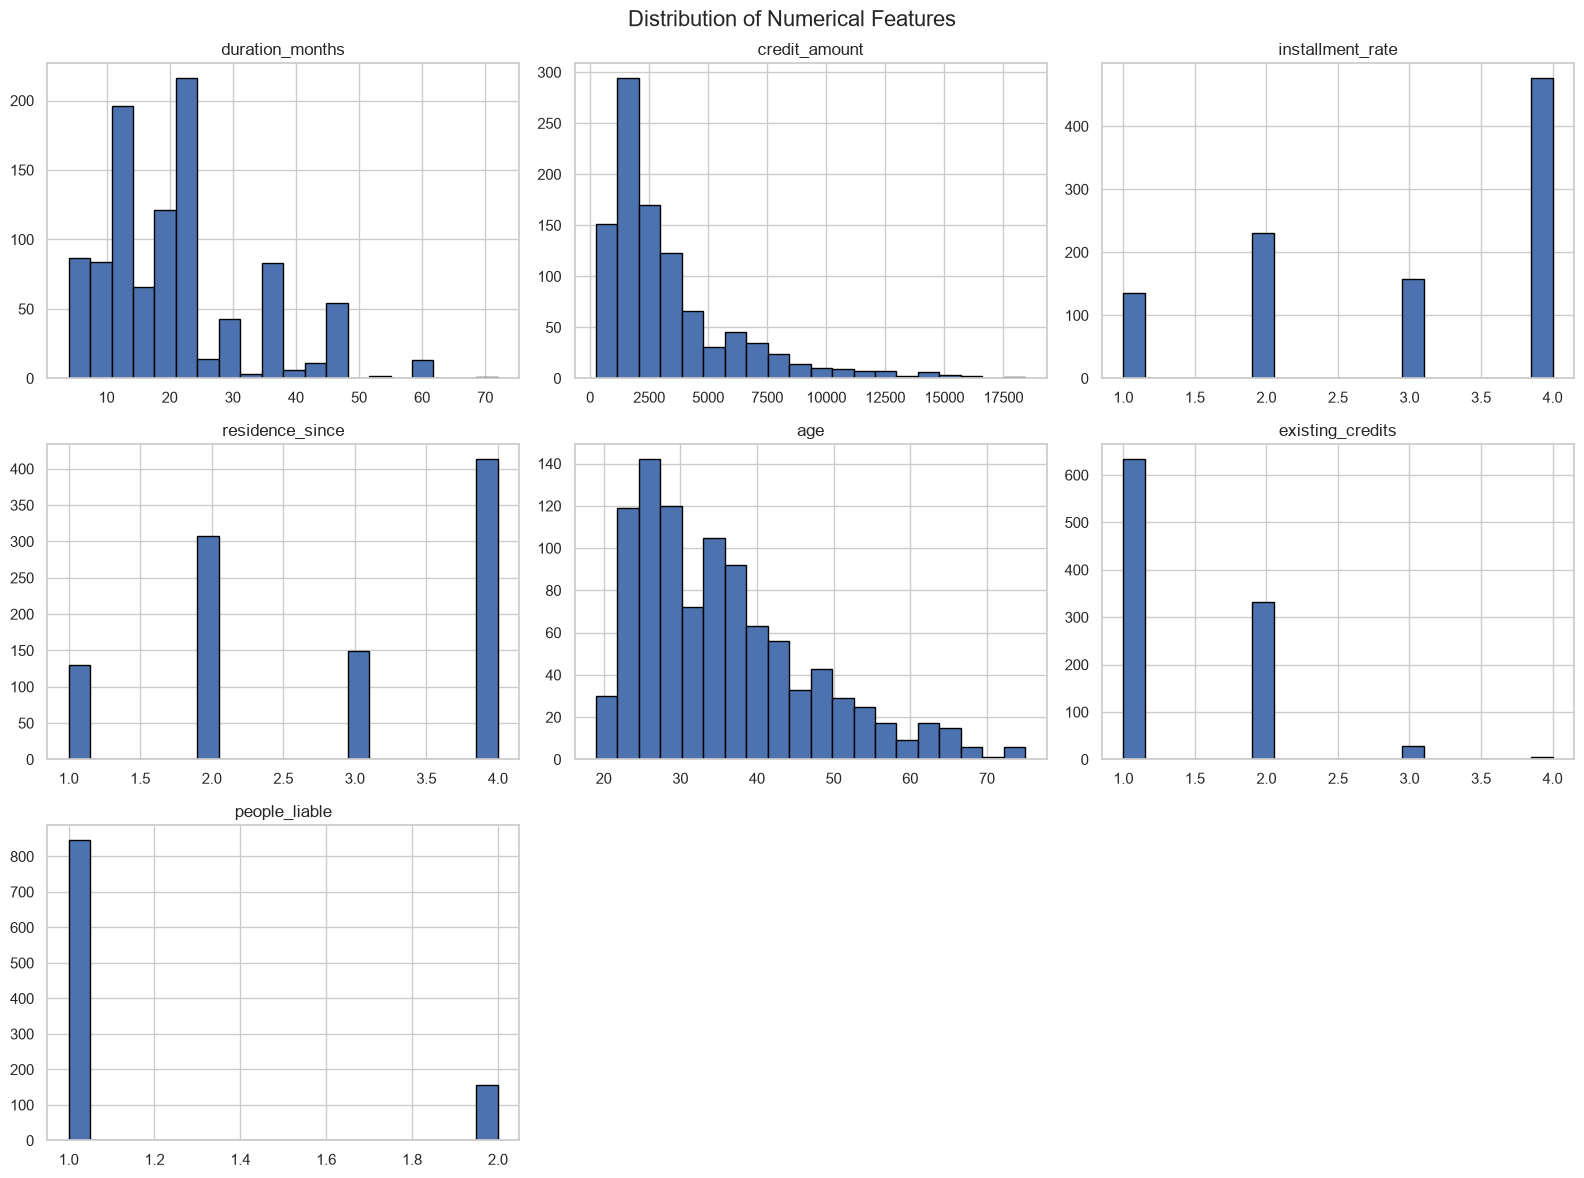

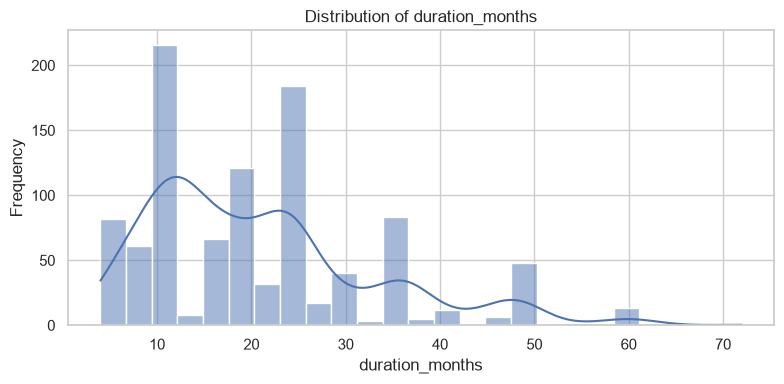

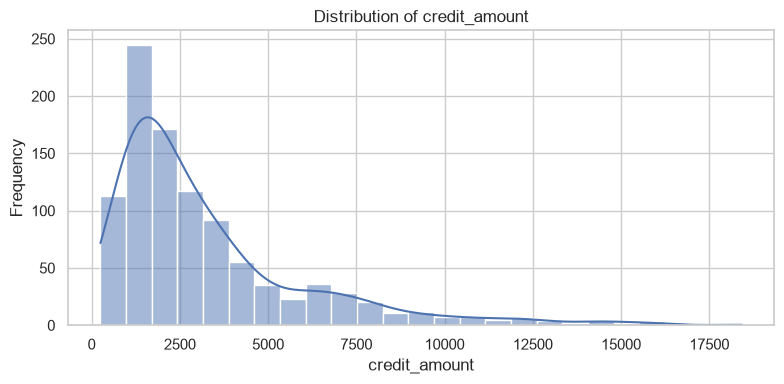

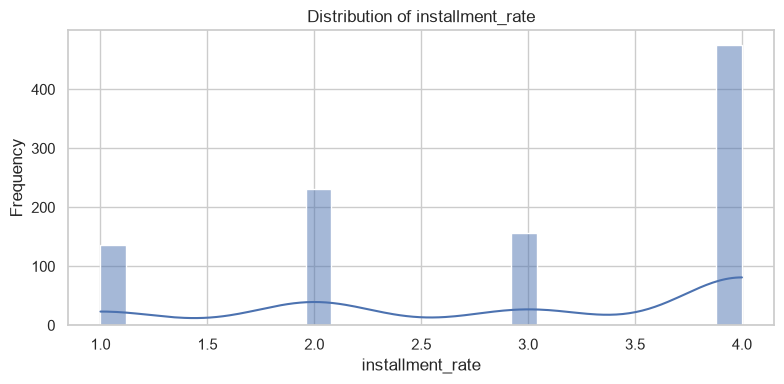

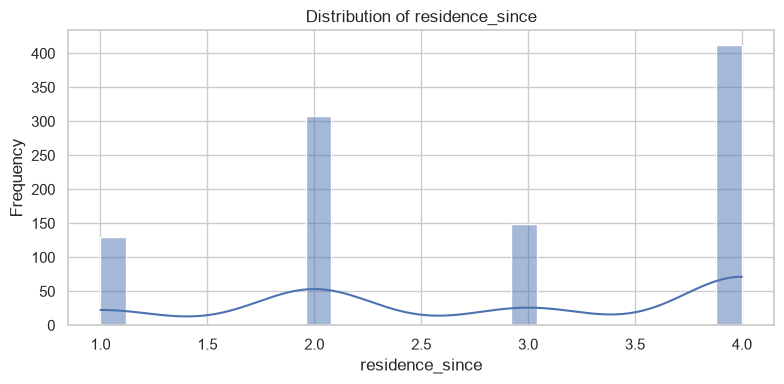

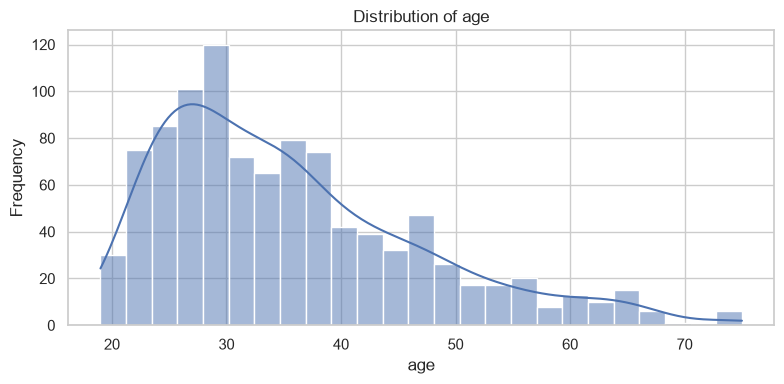

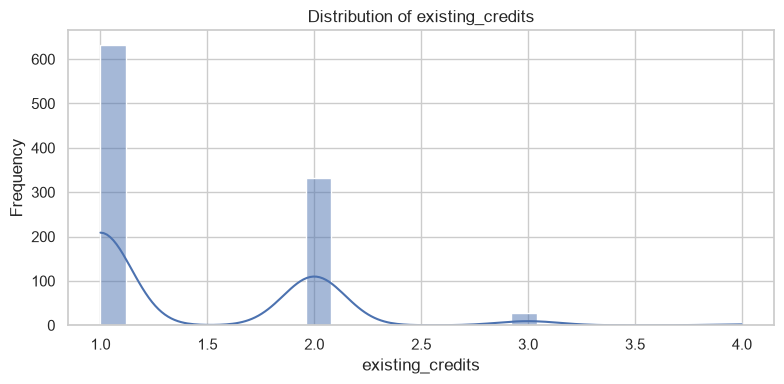

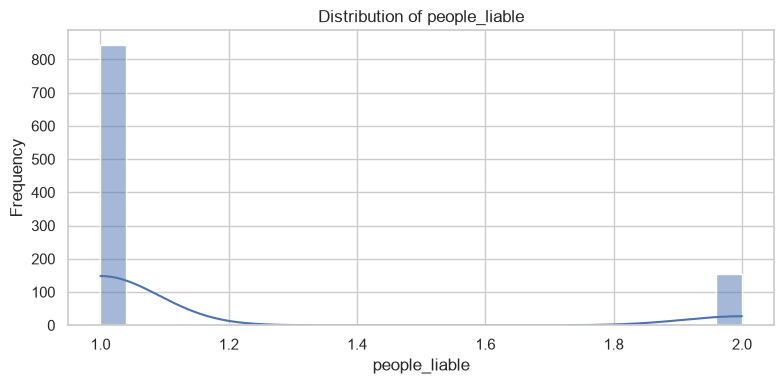


OUTLIER DETECTION SUMMARY


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,duration_months,12.0,24.00,12.00,-6.00,42.00,70,7.0
1,credit_amount,1365.5,3972.25,2606.75,-2544.62,7882.38,72,7.2
2,installment_rate,2.0,4.00,2.00,-1.00,7.00,0,0.0
3,residence_since,2.0,4.00,2.00,-1.00,7.00,0,0.0
4,age,27.0,42.00,15.00,4.50,64.50,23,2.3
5,existing_credits,1.0,2.00,1.00,-0.50,3.50,6,0.6
6,people_liable,1.0,1.00,0.00,1.00,1.00,155,15.5


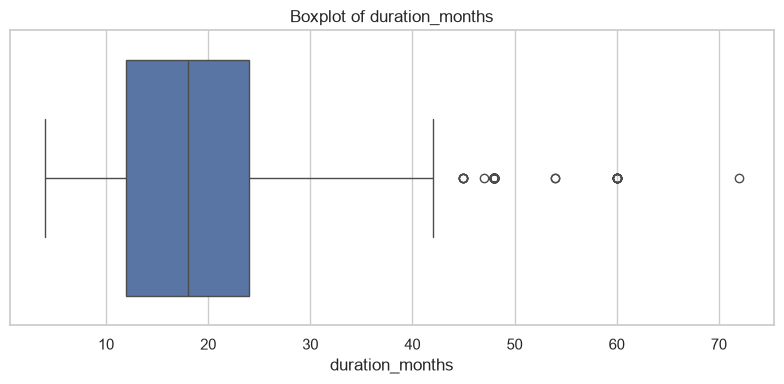

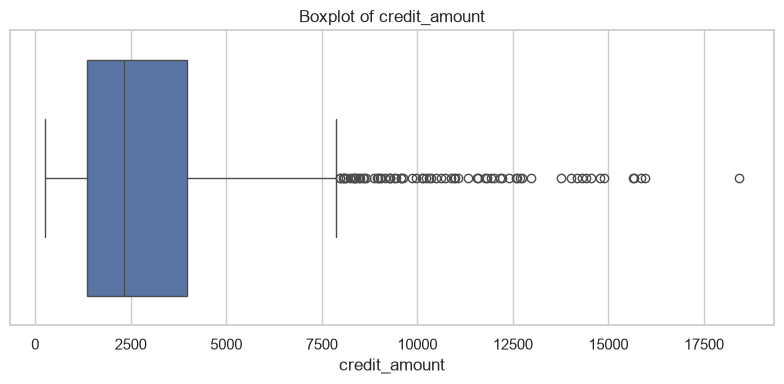

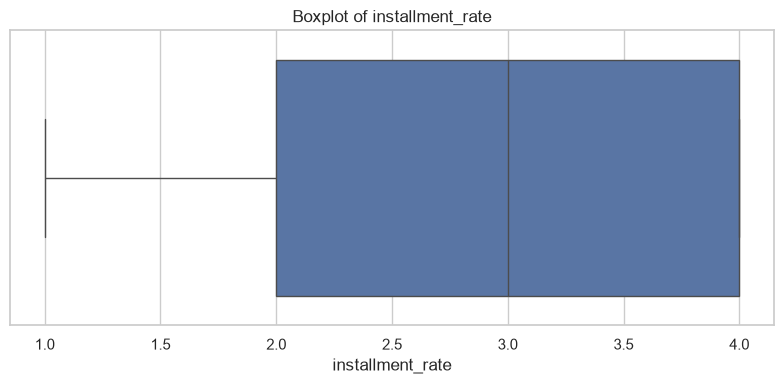

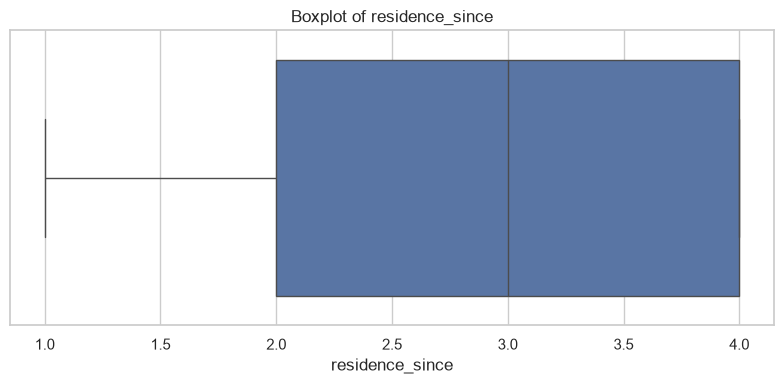

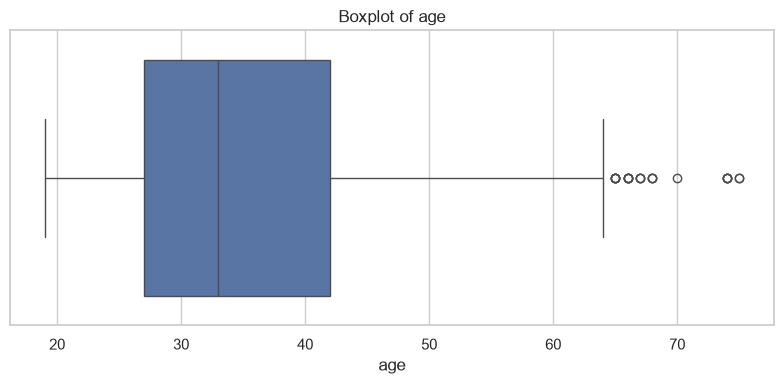

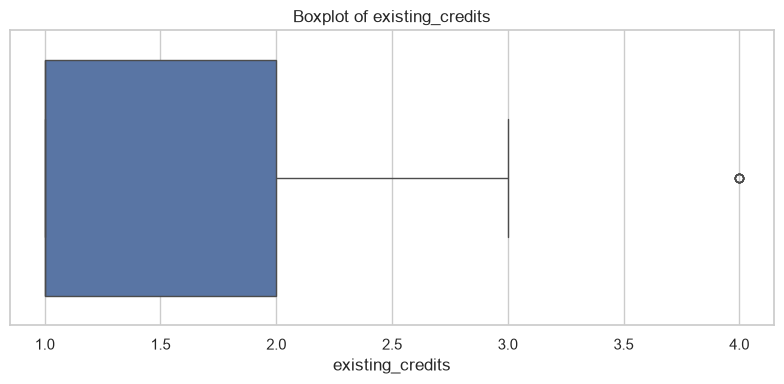

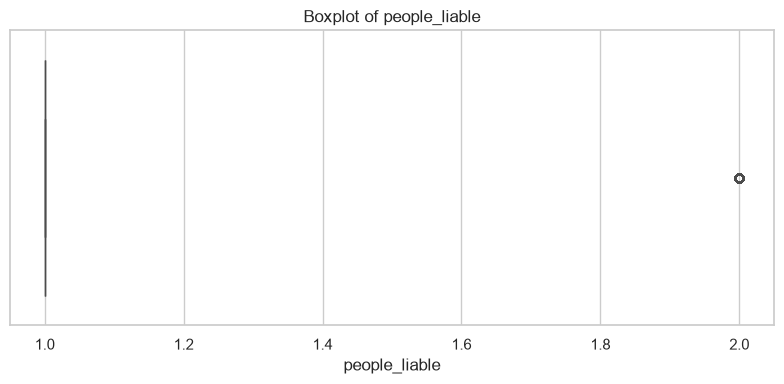

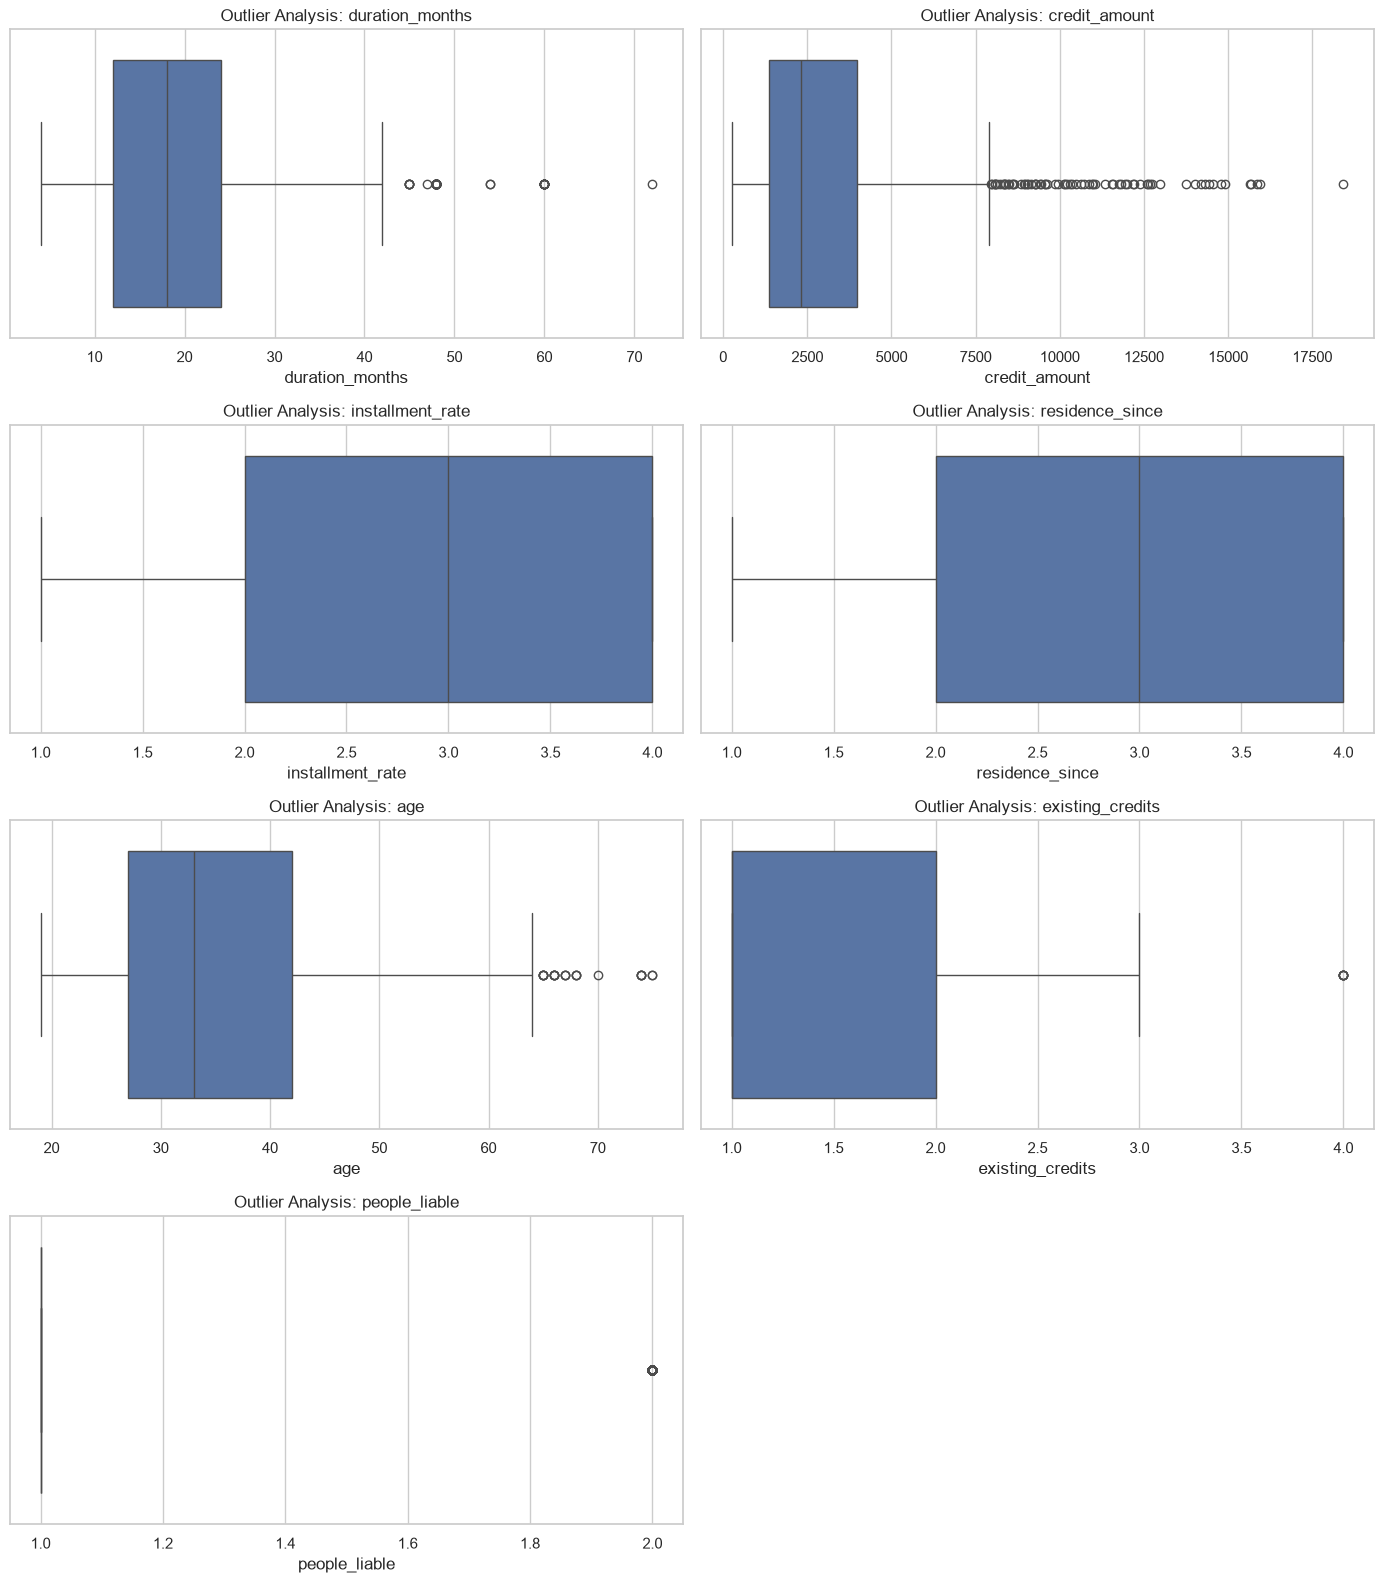

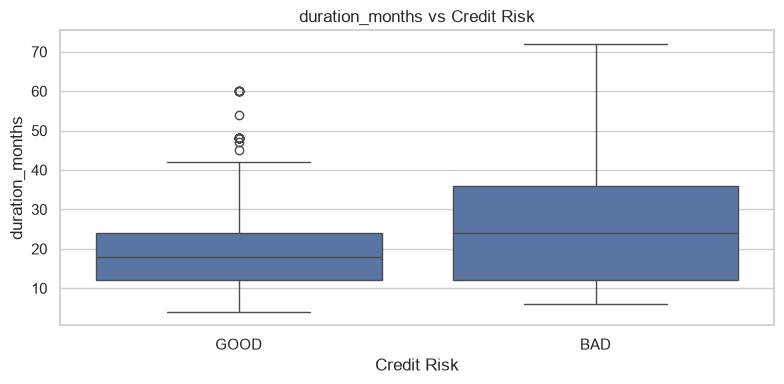

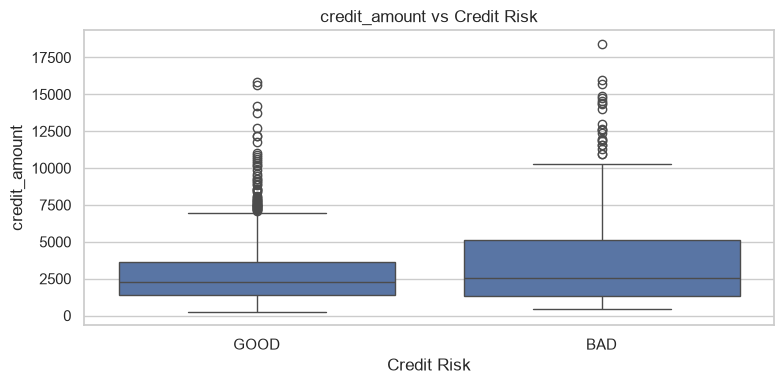

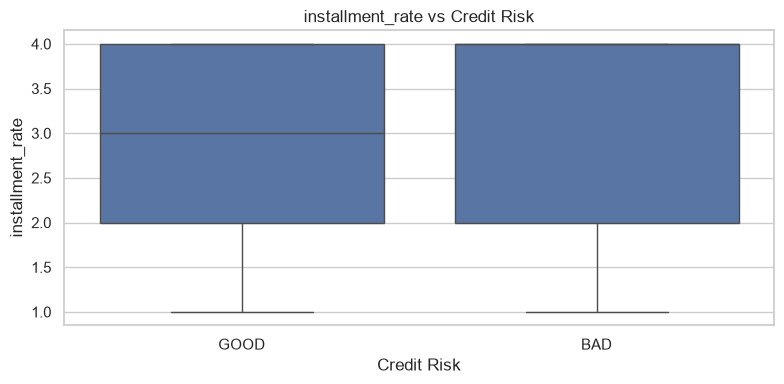

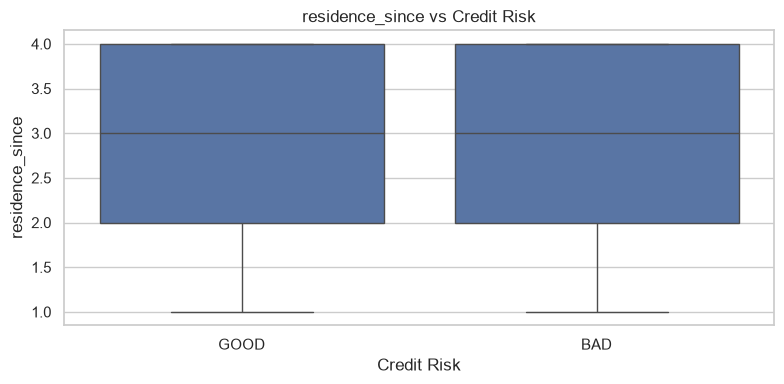

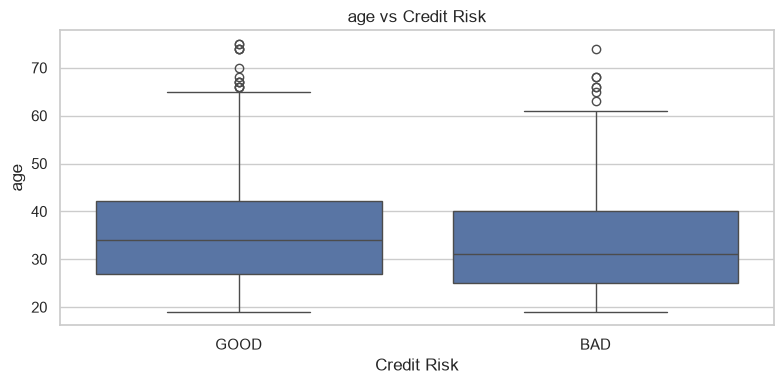

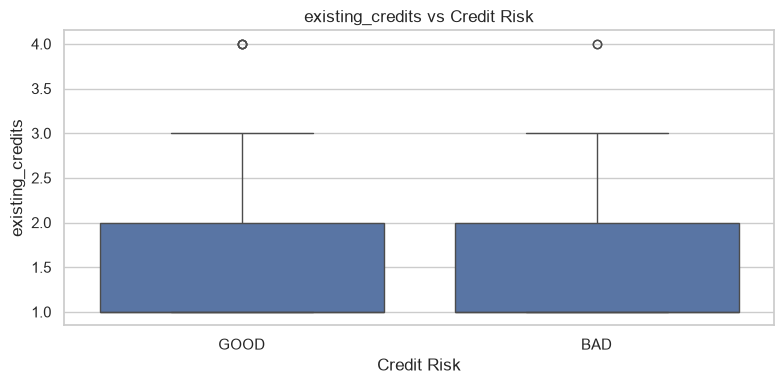

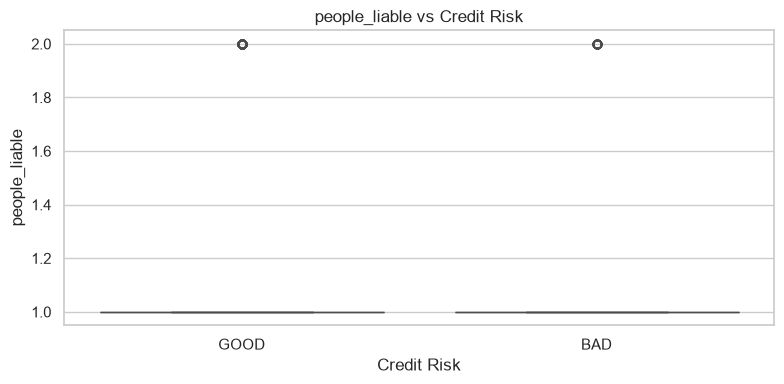


NUMERICAL FEATURES BY CREDIT RISK


duration_months               credit_amount                   \
                      mean median    std          mean  median      std   
risk_label                                                                
BAD                  24.86   24.0  13.28       3938.13  2574.5  3535.82   
GOOD                 19.21   18.0  11.08       2985.46  2244.0  2401.47   

           installment_rate              residence_since  ...          age  \
                       mean median   std            mean  ...   std   mean   
risk_label                                                ...                
BAD                    3.10    4.0  1.09            2.85  ...  1.09  33.96   
GOOD                   2.92    3.0  1.13            2.84  ...  1.11  36.22   

                         existing_credits              people_liable         \
           median    std             mean median   std          mean median   
risk_label                                                                    
BAD          31.0  11.22             1.37    1.0  0.56          1.15    1.0   
GOOD         34.0  11.38             1.42    1.0  0.58          1.16    1.0   

                  
             std  
risk_label        
BAD         0.36  
GOOD        0.36  

[2 rows x 21 columns]


DOMAIN INTERPRETATION
------------------------------------------------
duration_months: Right-skewed distribution.
credit_amount: Right-skewed distribution.
installment_rate: Left-skewed distribution.
residence_since: Approximately symmetric distribution.
age: Right-skewed distribution.
existing_credits: Right-skewed distribution.
people_liable: Right-skewed distribution.

FEATURE INTERPRETATIONS:
1. Duration: Longer repayment periods may increase credit exposure.
2. Credit Amount: Large loans may represent greater financial exposure.
3. Installment Rate: Represents repayment burden relative to income.
4. Residence Since: Describes customer residential stability.
5. Age: Helps explore age-related credit-risk patterns.
6. Existing Credits: Indicates the number of existing bank credits.
7. People Liable: Describes the number of people financially dependent on the customer.

PREPROCESSING RECOMMENDATIONS
------------------------------------------------
1. Investigate highly skewed numeri

In [3]:

# ============================================================
# SECTION 3: NUMERICAL FEATURES - DISTRIBUTIONS,
# SKEWNESS & OUTLIERS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. IDENTIFY NUMERICAL FEATURES
numerical_cols = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "people_liable"
]

print("Numerical Features:")
print(numerical_cols)
print("\nTotal Numerical Features:", len(numerical_cols))


# 2. DESCRIPTIVE STATISTICS
print("\nDESCRIPTIVE STATISTICS")
display(df[numerical_cols].describe().T)


# 3. SKEWNESS ANALYSIS
skewness = df[numerical_cols].skew()

skewness_summary = pd.DataFrame({
    "Skewness": skewness,
    "Distribution": [
        "Highly Right Skewed" if x > 1 else
        "Moderately Right Skewed" if x > 0.5 else
        "Highly Left Skewed" if x < -1 else
        "Moderately Left Skewed" if x < -0.5 else
        "Approximately Symmetric"
        for x in skewness
    ]
})

print("\nSKEWNESS ANALYSIS")
display(skewness_summary.round(3))


# 4. HISTOGRAMS AND KDE PLOTS
df[numerical_cols].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


# 5. INDIVIDUAL DISTRIBUTION PLOTS
for col in numerical_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=25
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 6. OUTLIER DETECTION USING IQR METHOD
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("\nOUTLIER DETECTION SUMMARY")
display(outlier_summary.round(2))


# 7. BOXPLOTS FOR OUTLIER VISUALIZATION
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=col
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


# 8. COMBINED BOXPLOTS
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flatten(), numerical_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Outlier Analysis: {col}")

for ax in axes.flatten()[len(numerical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


# 9. NUMERICAL FEATURES VS CREDIT RISK
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="risk_label",
        y=col,
        order=["GOOD", "BAD"]
    )

    plt.title(f"{col} vs Credit Risk")
    plt.xlabel("Credit Risk")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


# 10. GROUP-WISE NUMERICAL ANALYSIS
print("\nNUMERICAL FEATURES BY CREDIT RISK")

risk_comparison = df.groupby("risk_label")[numerical_cols].agg(
    ["mean", "median", "std"]
)

display(risk_comparison.round(2))


# 11. DOMAIN INTERPRETATION
print("\nDOMAIN INTERPRETATION")
print("------------------------------------------------")

for col in numerical_cols:

    feature_skew = df[col].skew()

    if feature_skew > 0.5:
        interpretation = "Right-skewed distribution."
    elif feature_skew < -0.5:
        interpretation = "Left-skewed distribution."
    else:
        interpretation = "Approximately symmetric distribution."

    print(f"{col}: {interpretation}")

print("\nFEATURE INTERPRETATIONS:")
print("1. Duration: Longer repayment periods may increase credit exposure.")
print("2. Credit Amount: Large loans may represent greater financial exposure.")
print("3. Installment Rate: Represents repayment burden relative to income.")
print("4. Residence Since: Describes customer residential stability.")
print("5. Age: Helps explore age-related credit-risk patterns.")
print("6. Existing Credits: Indicates the number of existing bank credits.")
print("7. People Liable: Describes the number of people financially dependent on the customer.")


# 12. PREPROCESSING RECOMMENDATIONS
print("\nPREPROCESSING RECOMMENDATIONS")
print("------------------------------------------------")
print("1. Investigate highly skewed numerical features.")
print("2. Consider log transformation for suitable positive variables.")
print("3. Investigate outliers before deciding how to handle them.")
print("4. Do not automatically delete extreme observations.")
print("5. Consider StandardScaler or RobustScaler during modelling.")
print("6. Fit transformations using training data only.")


# 13. FINAL SUMMARY
print("\n==============================================")
print("SECTION 3 COMPLETED SUCCESSFULLY")
print("==============================================")

print("Numerical Features Analyzed:", len(numerical_cols))
print("Distribution Analysis: Completed")
print("Skewness Analysis: Completed")
print("IQR Outlier Detection: Completed")
print("Boxplot Visualization: Completed")
print("Credit Risk Comparison: Completed")
print("Domain Interpretation: Completed")


## Section 4: Categorical Features: Frequency Auditing & Special Encodings (A65, A124)


### Interpretation

*Write your interpretation here.*


Total Categorical Features: 13

Categorical Features:
['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

UNIQUE CATEGORY AUDIT

Feature: checking_account
Unique Categories: 4
Category Values: ['A11', 'A12', 'A13', 'A14']

Feature: credit_history
Unique Categories: 5
Category Values: ['A30', 'A31', 'A32', 'A33', 'A34']

Feature: purpose
Unique Categories: 10
Category Values: ['A40', 'A41', 'A410', 'A42', 'A43', 'A44', 'A45', 'A46', 'A48', 'A49']

Feature: savings_account
Unique Categories: 5
Category Values: ['A61', 'A62', 'A63', 'A64', 'A65']

Feature: employment_duration
Unique Categories: 5
Category Values: ['A71', 'A72', 'A73', 'A74', 'A75']

Feature: personal_status_sex
Unique Categories: 4
Category Values: ['A91', 'A92', 'A93', 'A94']

Feature: other_debtors
Unique Categories: 3
Category Values: ['A101', 'A102', '

,Frequency,Percentage
checking_account,,
A14,394,39.4
A11,274,27.4
A12,269,26.9
A13,63,6.3



Feature: credit_history


,Frequency,Percentage
credit_history,,
A32,530,53.0
A34,293,29.3
A33,88,8.8
A31,49,4.9
A30,40,4.0



Feature: purpose


,Frequency,Percentage
purpose,,
A43,280,28.0
A40,234,23.4
A42,181,18.1
A41,103,10.3
A49,97,9.7
A46,50,5.0
A45,22,2.2
A44,12,1.2
A410,12,1.2


... (19 outputs left out)

,Frequency,Percentage
foreign_worker,,
A201,963,96.3
A202,37,3.7



MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
checking_account,0,0.0
credit_history,0,0.0
purpose,0,0.0
savings_account,0,0.0
employment_duration,0,0.0
personal_status_sex,0,0.0
other_debtors,0,0.0
property,0,0.0
other_installment_plans,0,0.0
housing,0,0.0


Total Missing Categorical Values: 0

A65 SPECIAL CATEGORY VERIFICATION
A65 Frequency:
183

Savings Account Distribution:
savings_account
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

A65 VERIFIED: Retained as a valid category.
Meaning: Unknown or no savings account.

A124 SPECIAL CATEGORY VERIFICATION
A124 Frequency:
154

Property Distribution:
property
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

A124 VERIFIED: Retained as a valid category.
Meaning: Unknown or no property.


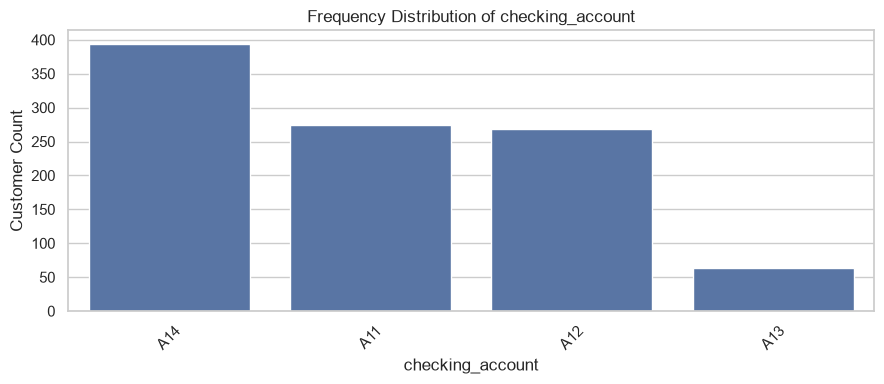

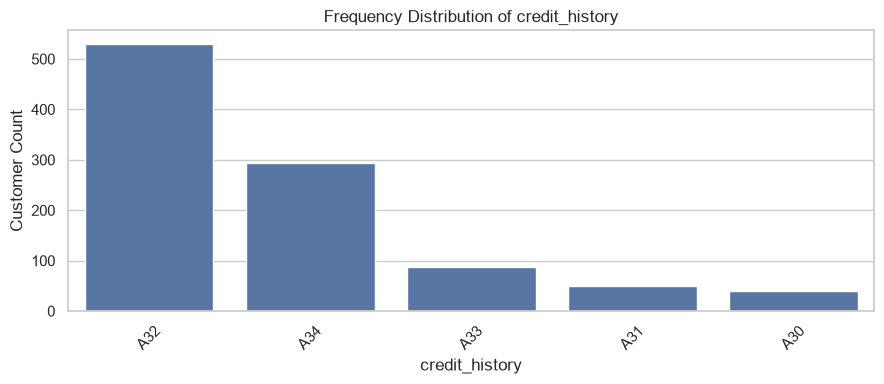

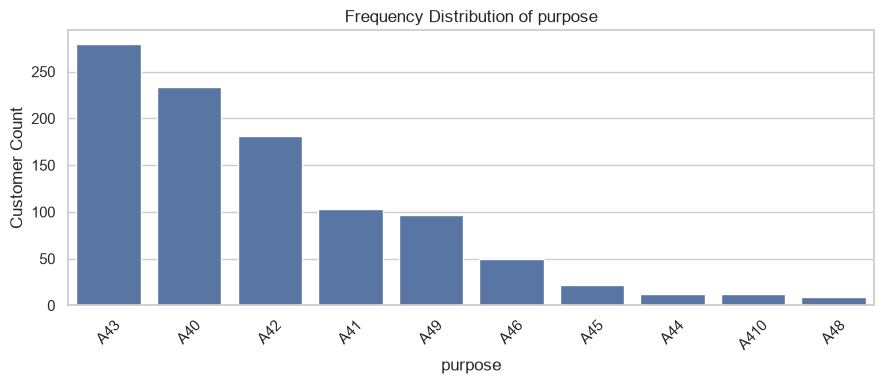

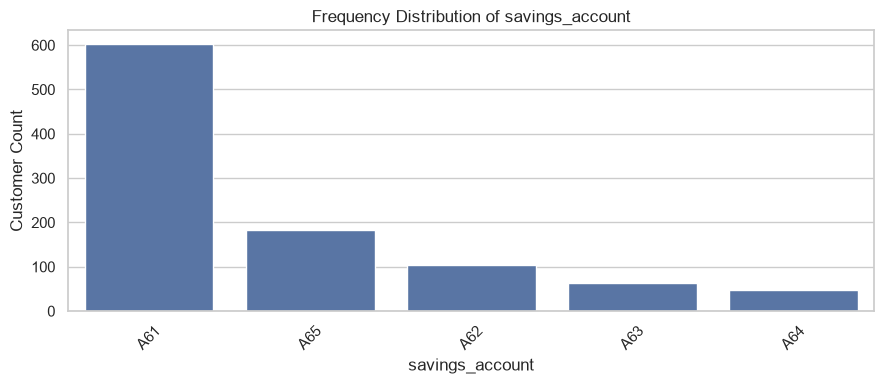

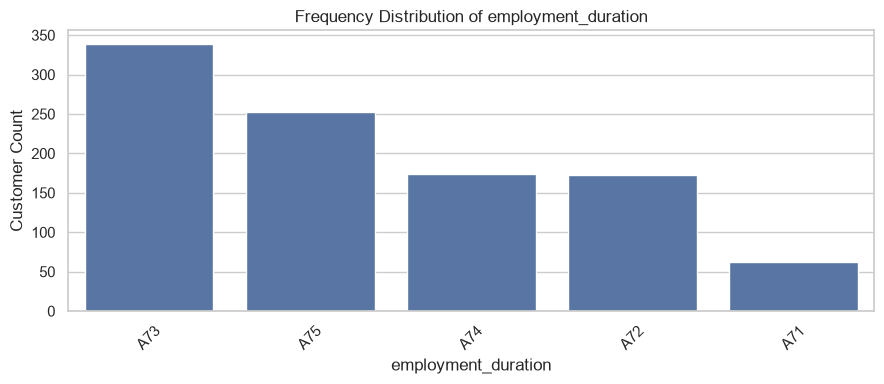

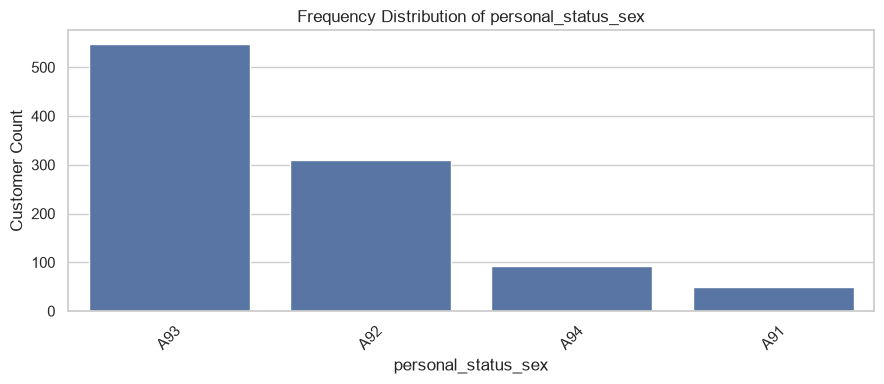

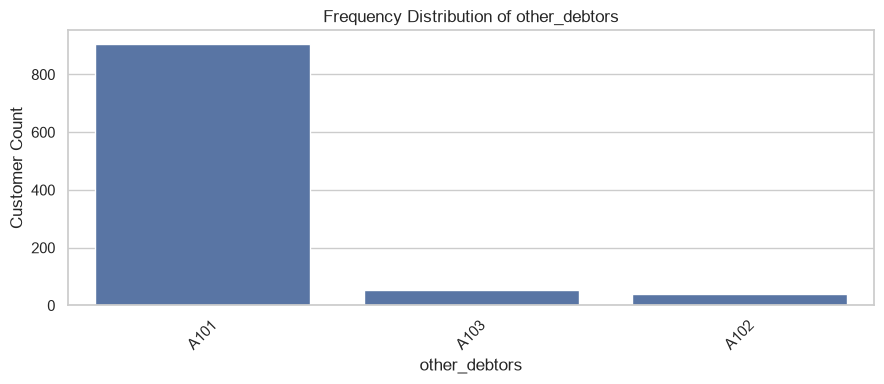

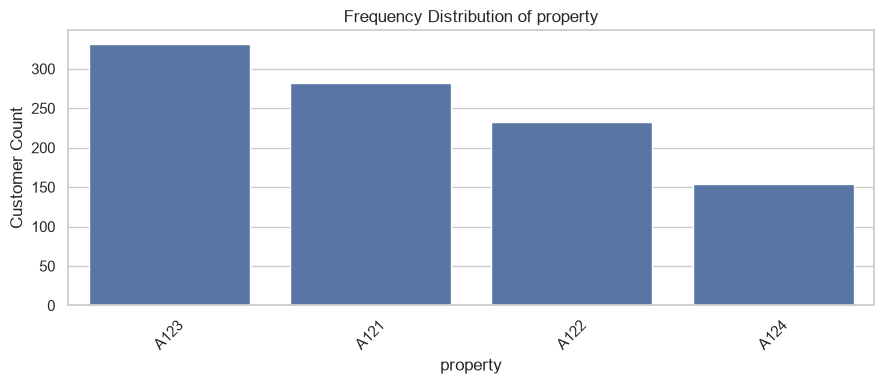

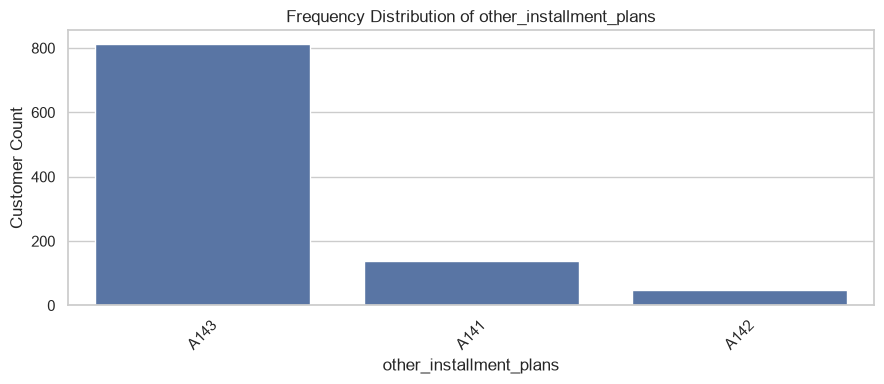

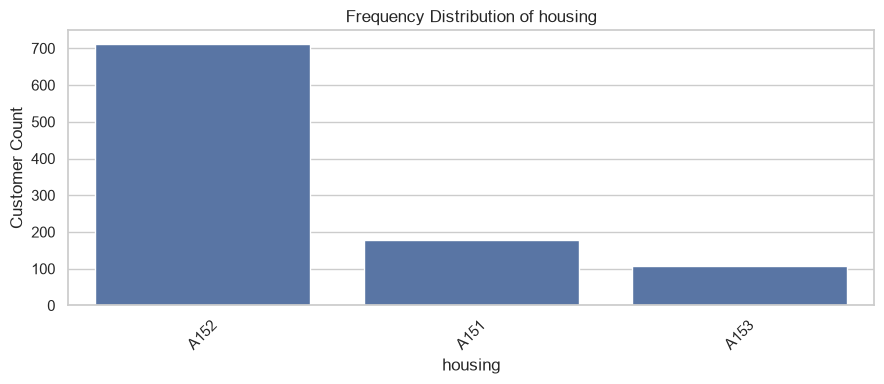

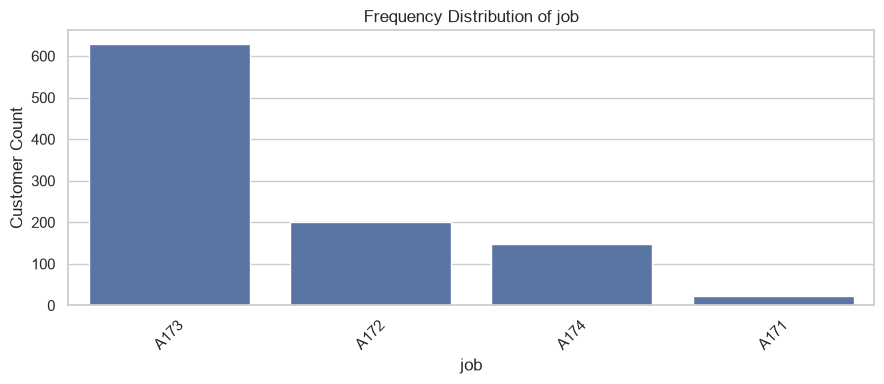

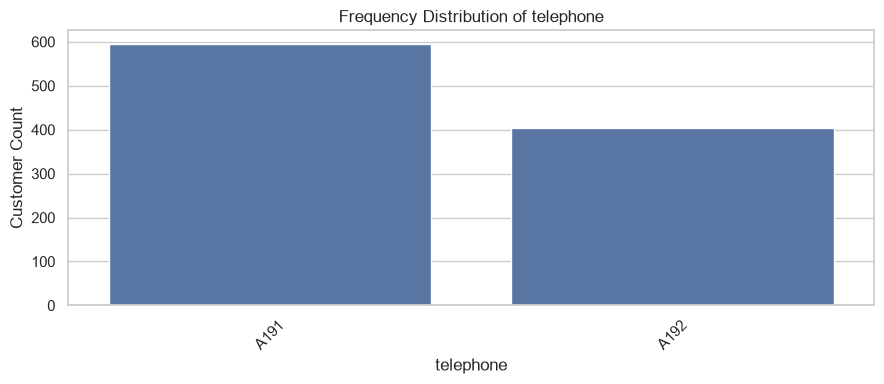

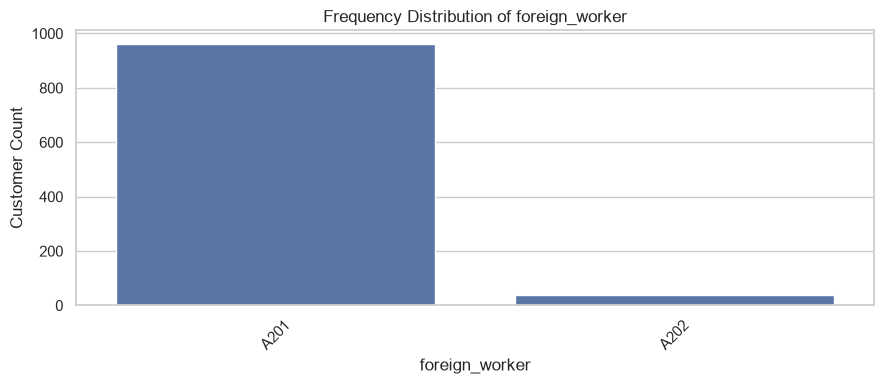

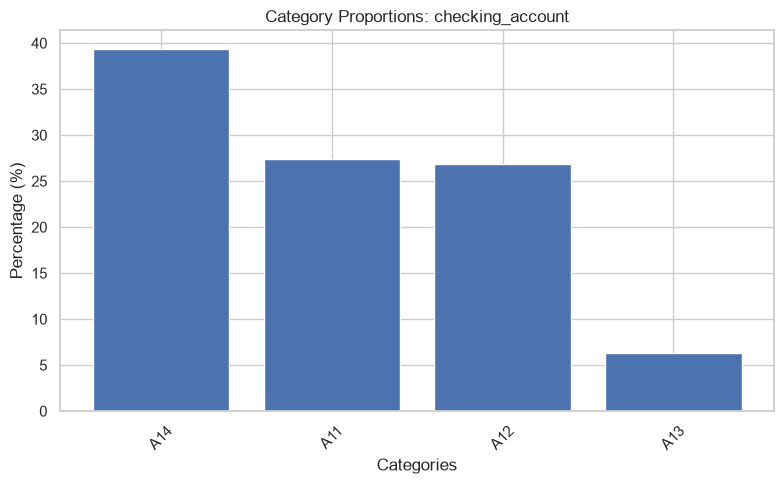

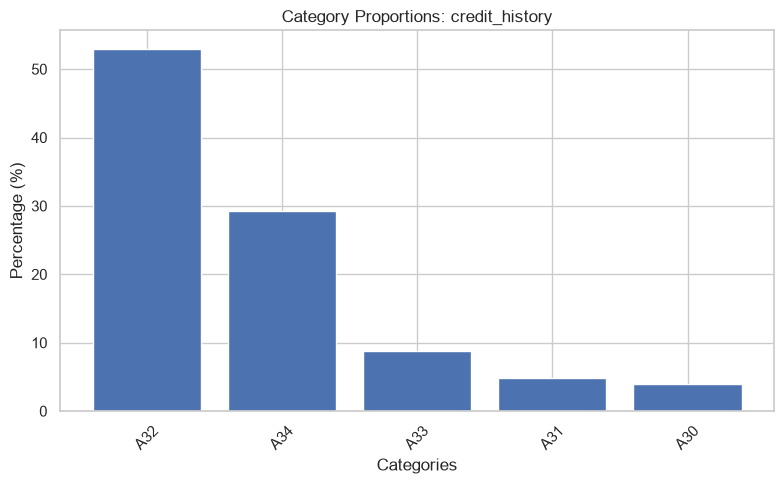

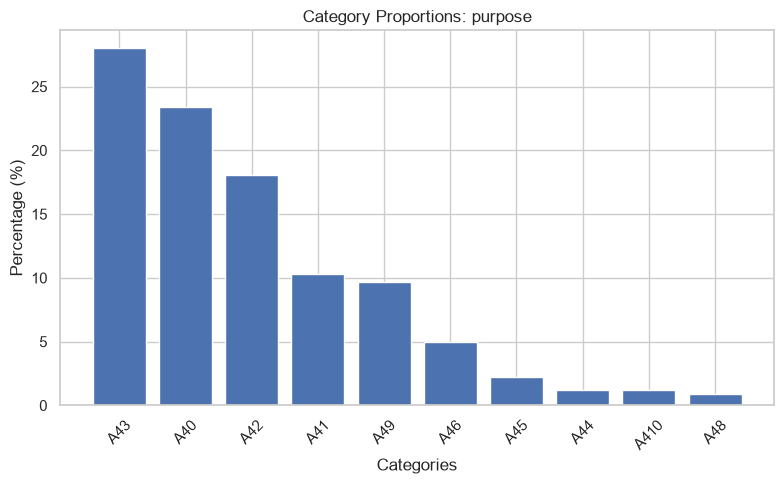

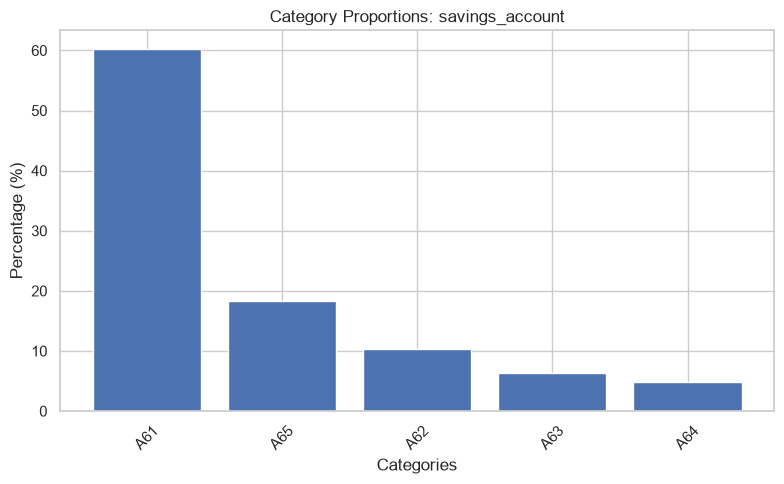

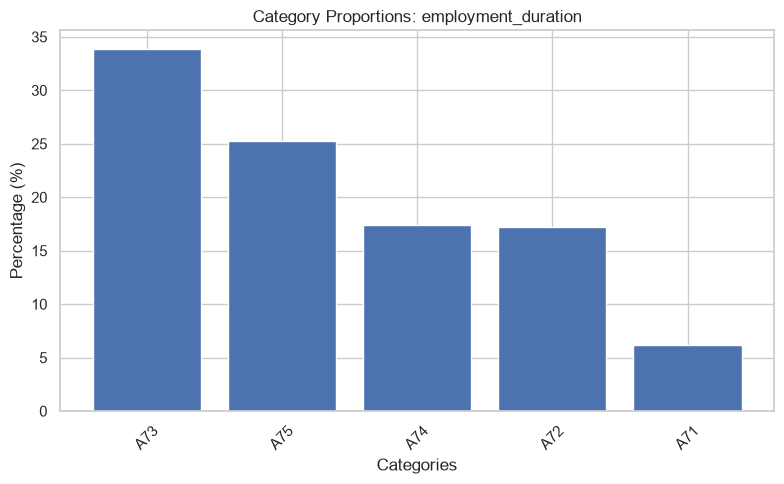

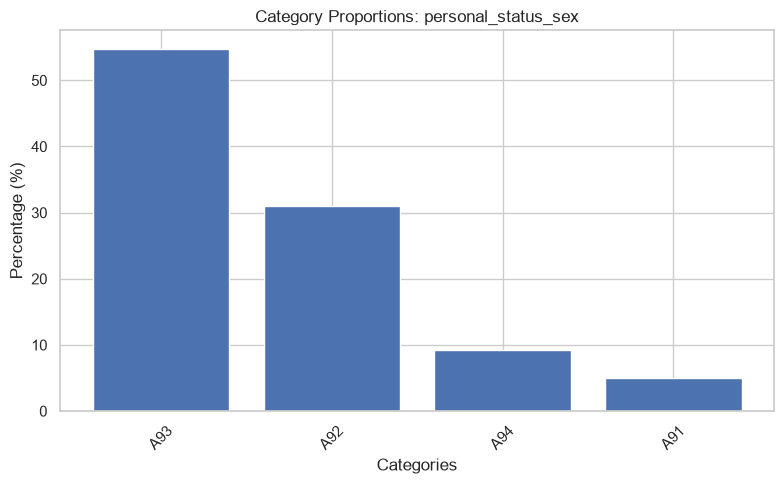

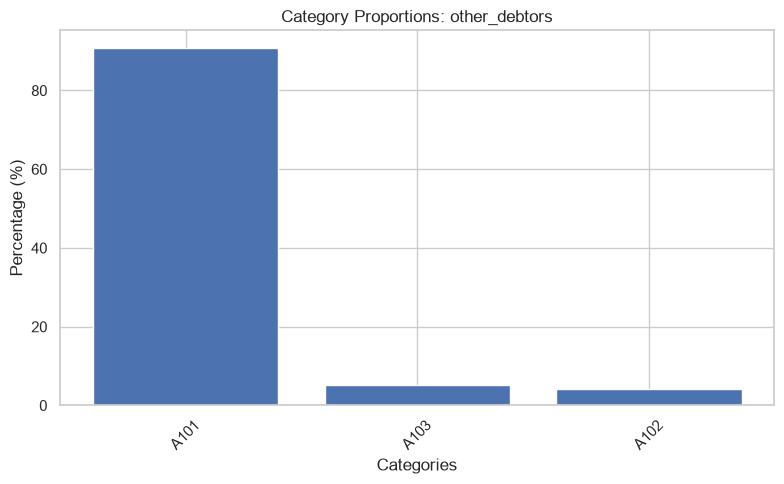

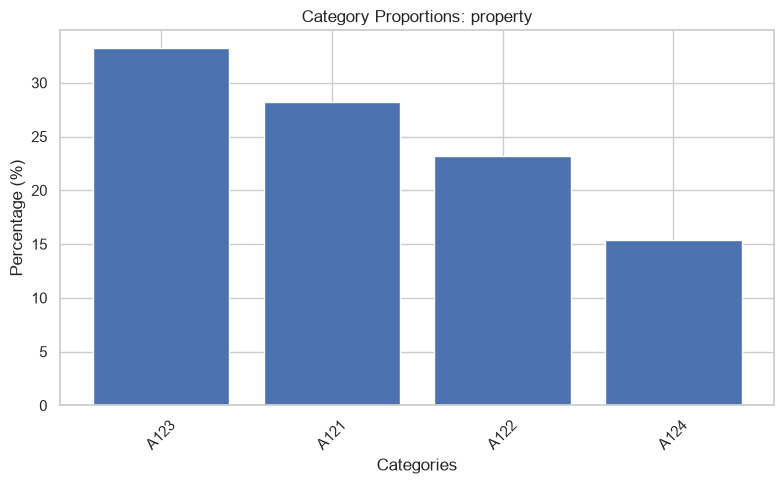

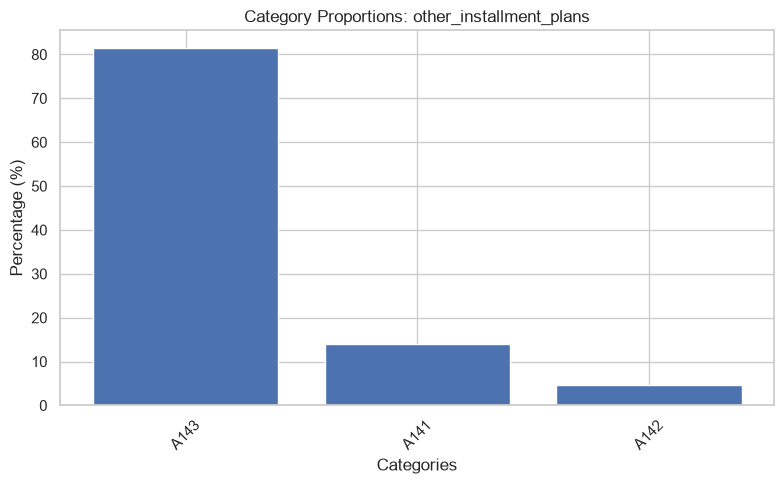

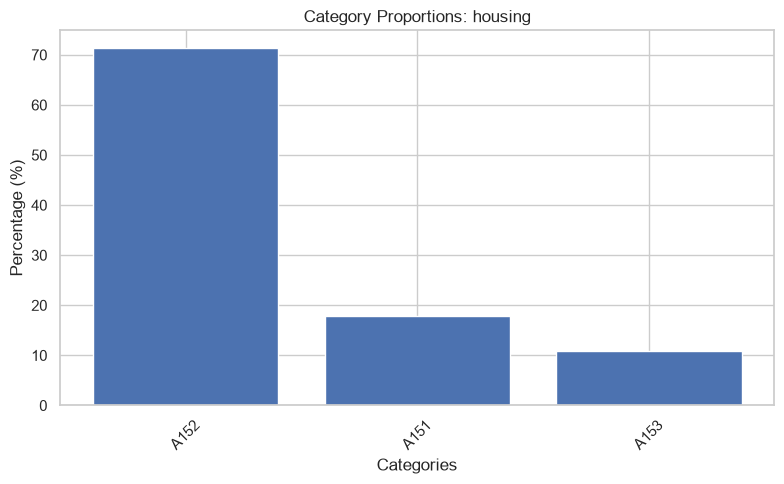

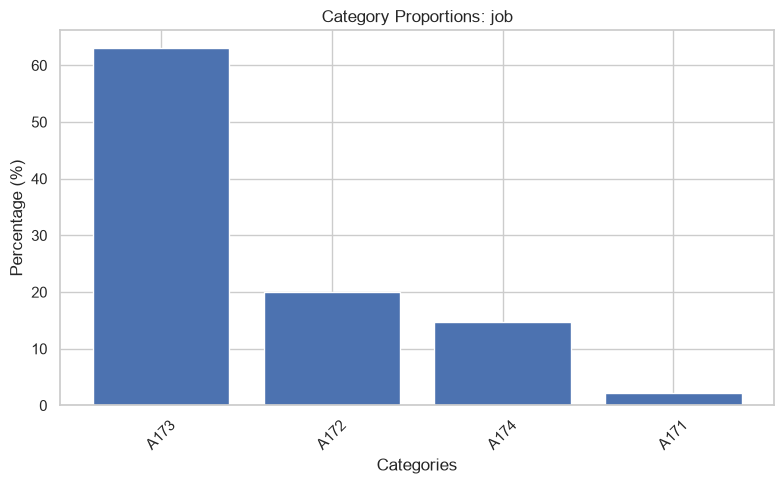

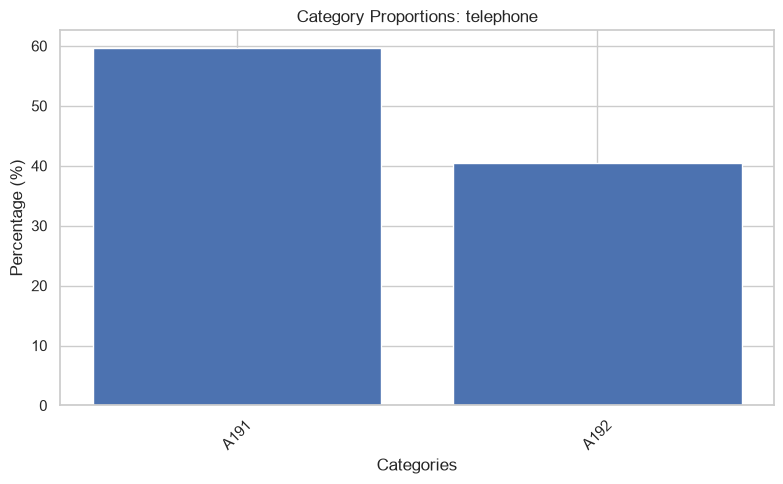

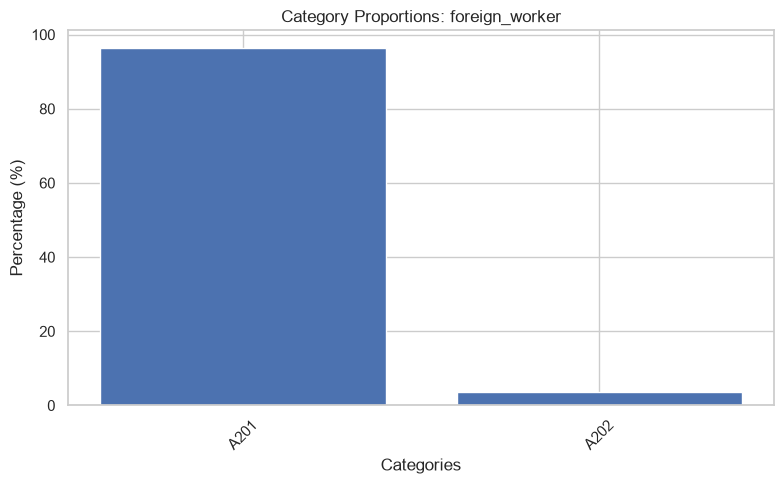


CATEGORICAL FEATURES VS CREDIT RISK

Credit Risk Analysis: checking_account


,Customer_Count,Bad_Credit_Rate
checking_account,,
A11,274,49.27
A12,269,39.03
A13,63,22.22
A14,394,11.68


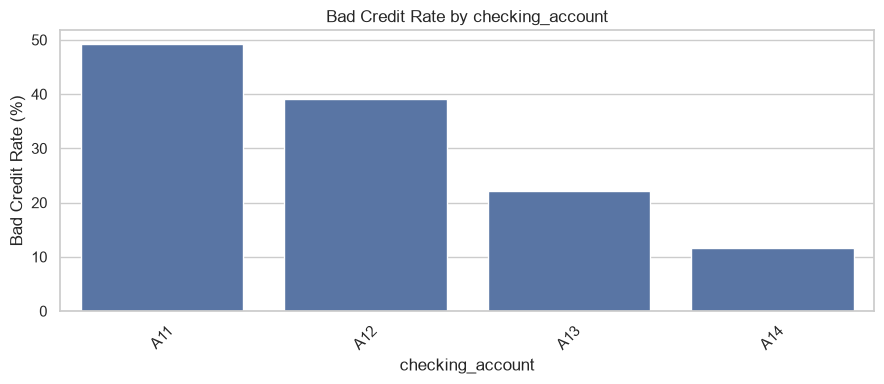


Credit Risk Analysis: credit_history


,Customer_Count,Bad_Credit_Rate
credit_history,,
A30,40,62.50
A31,49,57.14
A32,530,31.89
A33,88,31.82
A34,293,17.06


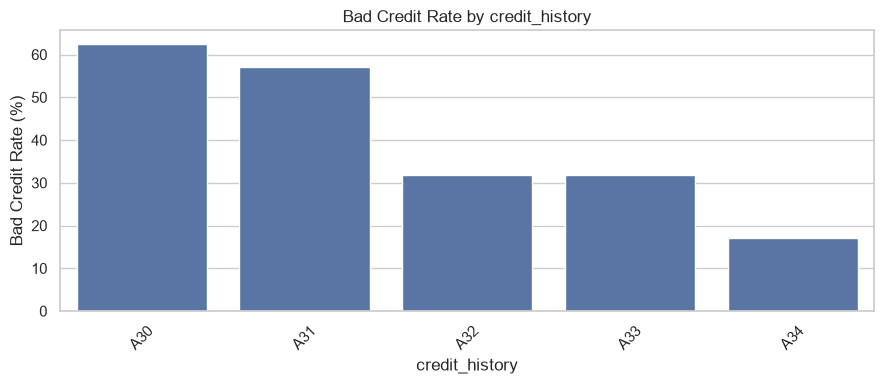


Credit Risk Analysis: purpose


,Customer_Count,Bad_Credit_Rate
purpose,,
A40,234,38.03
A41,103,16.50
A410,12,41.67
A42,181,32.04
A43,280,22.14
A44,12,33.33
A45,22,36.36
A46,50,44.00
A48,9,11.11


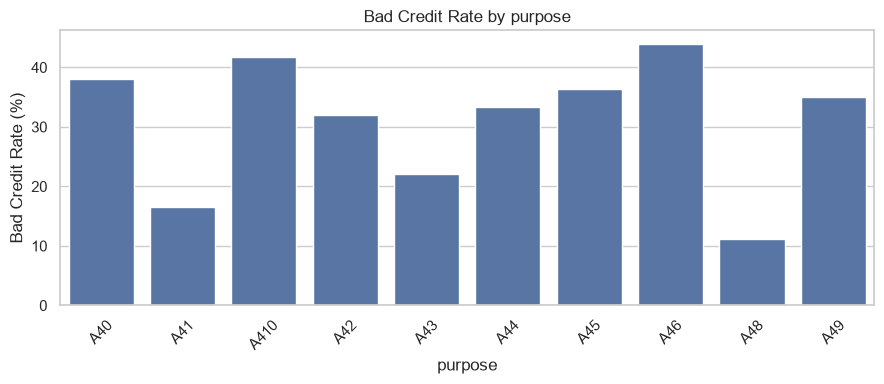


Credit Risk Analysis: savings_account


,Customer_Count,Bad_Credit_Rate
savings_account,,
A61,603,35.99
A62,103,33.01
A63,63,17.46
A64,48,12.50
A65,183,17.49


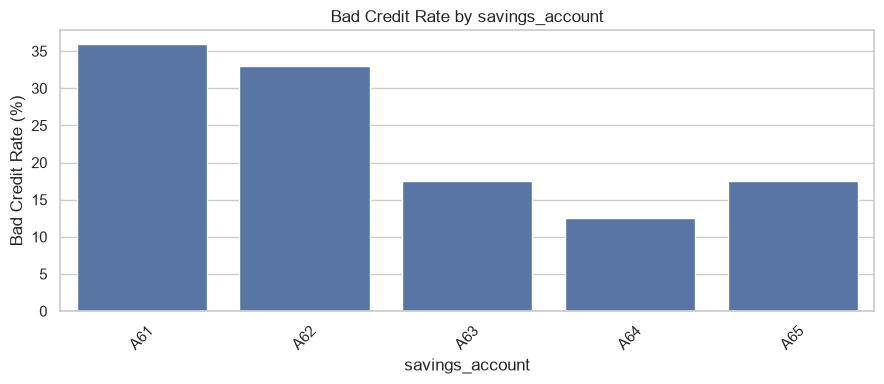


Credit Risk Analysis: employment_duration


,Customer_Count,Bad_Credit_Rate
employment_duration,,
A71,62,37.10
A72,172,40.70
A73,339,30.68
A74,174,22.41
A75,253,25.30


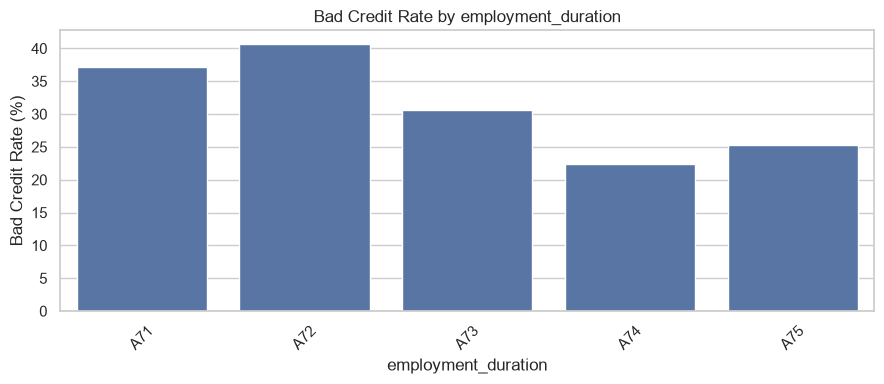


Credit Risk Analysis: personal_status_sex


,Customer_Count,Bad_Credit_Rate
personal_status_sex,,
A91,50,40.00
A92,310,35.16
A93,548,26.64
A94,92,27.17


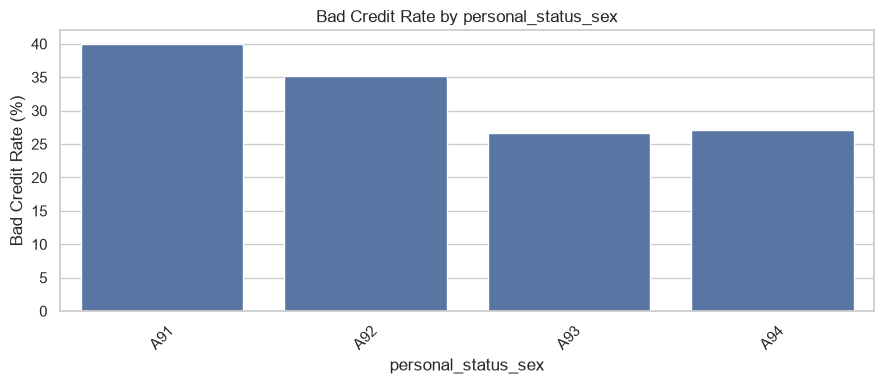


Credit Risk Analysis: other_debtors


,Customer_Count,Bad_Credit_Rate
other_debtors,,
A101,907,29.99
A102,41,43.90
A103,52,19.23


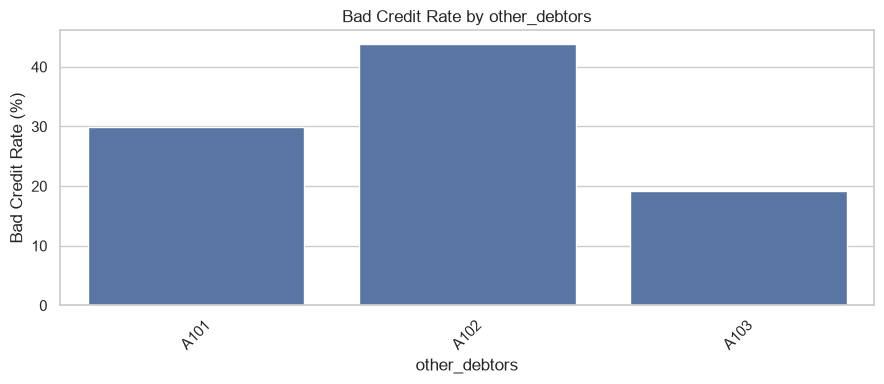


Credit Risk Analysis: property


,Customer_Count,Bad_Credit_Rate
property,,
A121,282,21.28
A122,232,30.60
A123,332,30.72
A124,154,43.51


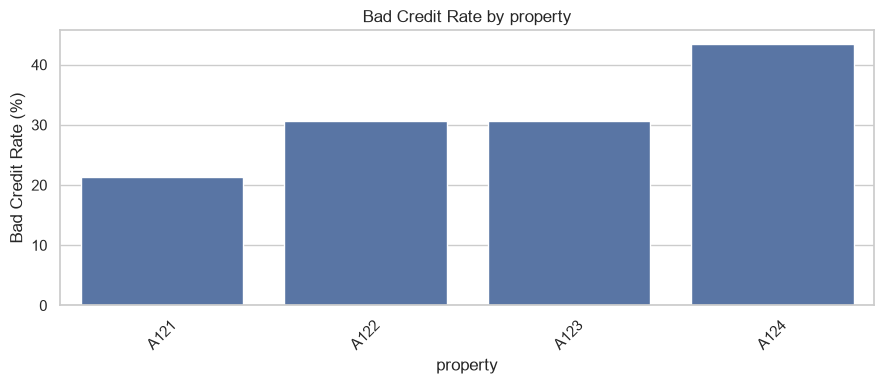


Credit Risk Analysis: other_installment_plans


,Customer_Count,Bad_Credit_Rate
other_installment_plans,,
A141,139,41.01
A142,47,40.43
A143,814,27.52


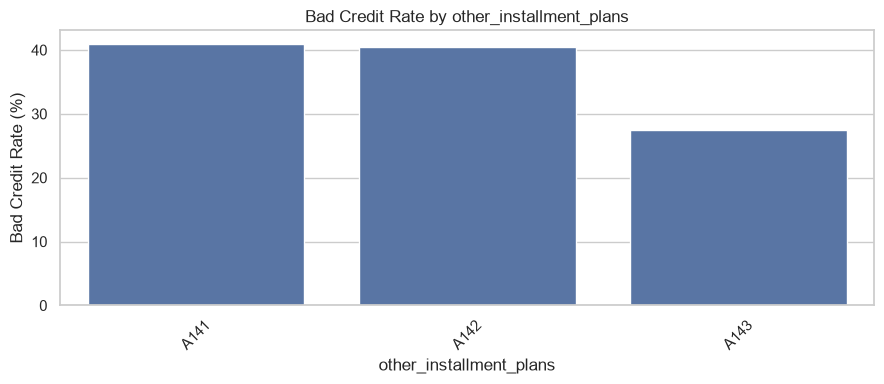


Credit Risk Analysis: housing


,Customer_Count,Bad_Credit_Rate
housing,,
A151,179,39.11
A152,713,26.09
A153,108,40.74


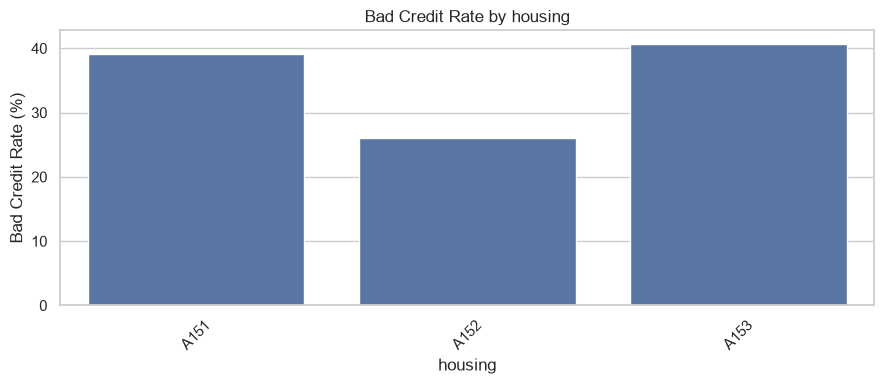


Credit Risk Analysis: job


,Customer_Count,Bad_Credit_Rate
job,,
A171,22,31.82
A172,200,28.00
A173,630,29.52
A174,148,34.46


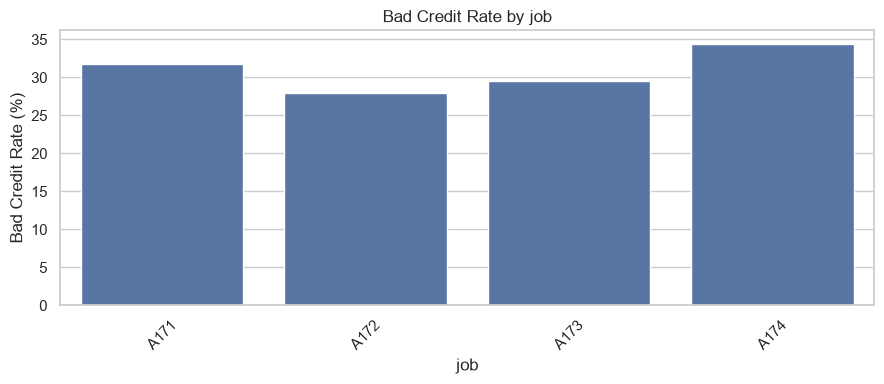


Credit Risk Analysis: telephone


,Customer_Count,Bad_Credit_Rate
telephone,,
A191,596,31.38
A192,404,27.97


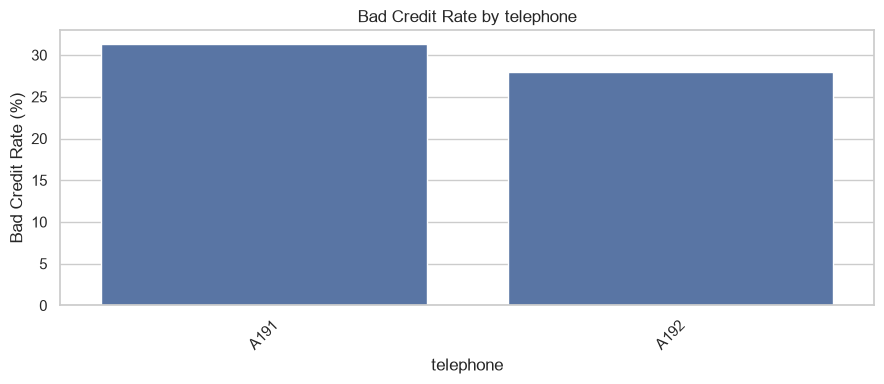


Credit Risk Analysis: foreign_worker


,Customer_Count,Bad_Credit_Rate
foreign_worker,,
A201,963,30.74
A202,37,10.81


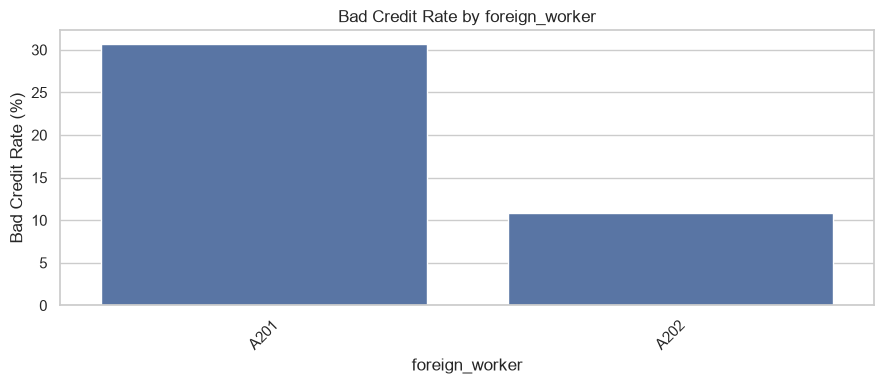


SPECIAL CATEGORY CREDIT RISK ANALYSIS

A65 Credit Risk Distribution:
risk_label
BAD      32
GOOD    151
dtype: int64

A124 Credit Risk Distribution:
risk_label
BAD     67
GOOD    87
dtype: int64

DOMAIN INTERPRETATION
1. Checking account categories describe customers' account status.
2. Credit history provides information about previous repayment behaviour.
3. Savings categories describe available savings information.
4. Employment duration indicates employment stability.
5. Property categories describe customer property information.
6. Housing categories describe accommodation status.
7. A65 represents unknown or no savings account.
8. A124 represents unknown or no property.
9. A65 and A124 are valid categorical values, not missing values.
10. Category-wise BAD credit rates help explore credit-risk patterns.

PREPROCESSING RECOMMENDATIONS
1. Preserve all original categorical codes.
2. Do not convert A65 or A124 into NaN.
3. Use One-Hot Encoding for nominal categorical features.
4. Co

In [4]:

# ============================================================
# SECTION 4: CATEGORICAL FEATURES - FREQUENCY AUDITING
# & SPECIAL ENCODINGS (A65, A124)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. IDENTIFY CATEGORICAL FEATURES

categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_duration",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

print("Total Categorical Features:", len(categorical_cols))
print("\nCategorical Features:")
print(categorical_cols)


# 2. UNIQUE CATEGORY AUDITING

print("\nUNIQUE CATEGORY AUDIT")
print("=" * 60)

for col in categorical_cols:
    print(f"\nFeature: {col}")
    print("Unique Categories:", df[col].nunique())
    print("Category Values:", sorted(df[col].unique()))


# 3. FREQUENCY AND PERCENTAGE ANALYSIS

print("\nFREQUENCY AND PERCENTAGE ANALYSIS")
print("=" * 60)

for col in categorical_cols:

    frequency = df[col].value_counts(dropna=False)
    percentage = df[col].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    frequency_table = pd.DataFrame({
        "Frequency": frequency,
        "Percentage": percentage
    })

    print(f"\nFeature: {col}")
    display(frequency_table.round(2))


# 4. MISSING VALUE AUDIT

print("\nMISSING VALUE AUDIT")

missing_summary = pd.DataFrame({
    "Missing_Count": df[categorical_cols].isnull().sum(),
    "Missing_Percentage": (
        df[categorical_cols].isnull().mean() * 100
    )
})

display(missing_summary.round(2))

print("Total Missing Categorical Values:",
      df[categorical_cols].isnull().sum().sum())


# 5. SPECIAL CATEGORY VERIFICATION: A65

print("\nA65 SPECIAL CATEGORY VERIFICATION")
print("=" * 60)

print("A65 Frequency:")
print((df["savings_account"] == "A65").sum())

print("\nSavings Account Distribution:")
print(df["savings_account"].value_counts())

assert "A65" in df["savings_account"].unique()
assert df.loc[
    df["savings_account"] == "A65",
    "savings_account"
].notna().all()

print("\nA65 VERIFIED: Retained as a valid category.")
print("Meaning: Unknown or no savings account.")


# 6. SPECIAL CATEGORY VERIFICATION: A124

print("\nA124 SPECIAL CATEGORY VERIFICATION")
print("=" * 60)

print("A124 Frequency:")
print((df["property"] == "A124").sum())

print("\nProperty Distribution:")
print(df["property"].value_counts())

assert "A124" in df["property"].unique()
assert df.loc[
    df["property"] == "A124",
    "property"
].notna().all()

print("\nA124 VERIFIED: Retained as a valid category.")
print("Meaning: Unknown or no property.")


# 7. VISUALIZE CATEGORICAL FREQUENCIES

for col in categorical_cols:

    plt.figure(figsize=(9, 4))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 8. CATEGORICAL PROPORTION ANALYSIS

for col in categorical_cols:

    proportions = (
        df[col].value_counts(normalize=True) * 100
    )

    plt.figure(figsize=(8, 5))

    plt.bar(
        proportions.index.astype(str),
        proportions.values
    )

    plt.title(f"Category Proportions: {col}")
    plt.xlabel("Categories")
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 9. CATEGORICAL FEATURES VS CREDIT RISK

print("\nCATEGORICAL FEATURES VS CREDIT RISK")
print("=" * 60)

for col in categorical_cols:

    risk_table = (
        df.groupby(col, observed=True)["credit_risk"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    risk_table["Bad_Credit_Rate"] *= 100

    print(f"\nCredit Risk Analysis: {col}")
    display(risk_table.round(2))

    #plotting block
    plot_data = risk_table.reset_index()

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=plot_data,
        x=col,
        y="Bad_Credit_Rate"
    )

    plt.title(f"Bad Credit Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Bad Credit Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 10. SPECIAL CATEGORY VS CREDIT RISK

print("\nSPECIAL CATEGORY CREDIT RISK ANALYSIS")

special_category_analysis = df[
    df["savings_account"] == "A65"
].groupby("risk_label").size()

print("\nA65 Credit Risk Distribution:")
print(special_category_analysis)

special_category_analysis_2 = df[
    df["property"] == "A124"
].groupby("risk_label").size()

print("\nA124 Credit Risk Distribution:")
print(special_category_analysis_2)


# 11. DOMAIN INTERPRETATION

print("\nDOMAIN INTERPRETATION")
print("=" * 60)

print("1. Checking account categories describe customers' account status.")
print("2. Credit history provides information about previous repayment behaviour.")
print("3. Savings categories describe available savings information.")
print("4. Employment duration indicates employment stability.")
print("5. Property categories describe customer property information.")
print("6. Housing categories describe accommodation status.")
print("7. A65 represents unknown or no savings account.")
print("8. A124 represents unknown or no property.")
print("9. A65 and A124 are valid categorical values, not missing values.")
print("10. Category-wise BAD credit rates help explore credit-risk patterns.")


# 12. PREPROCESSING RECOMMENDATIONS

print("\nPREPROCESSING RECOMMENDATIONS")
print("=" * 60)

print("1. Preserve all original categorical codes.")
print("2. Do not convert A65 or A124 into NaN.")
print("3. Use One-Hot Encoding for nominal categorical features.")
print("4. Consider Ordinal Encoding only where a meaningful order exists.")
print("5. Handle unknown categories consistently.")
print("6. Fit encoders using training data only.")
print("7. Check category frequencies before encoding.")


# 13. FINAL VALIDATION

assert len(categorical_cols) == 13
assert "A65" in df["savings_account"].values
assert "A124" in df["property"].values
assert df["savings_account"].isnull().sum() == 0
assert df["property"].isnull().sum() == 0

print("\n==============================================")
print("SECTION 4 COMPLETED SUCCESSFULLY")
print("==============================================")

print("Categorical Features Audited:", len(categorical_cols))
print("Frequency Analysis: Completed")
print("Percentage Analysis: Completed")
print("A65 Verification: PASSED")
print("A124 Verification: PASSED")
print("Missing Value Audit: Completed")
print("Credit Risk Analysis: Completed")
print("Domain Interpretation: Completed")


## Section 5: Bivariate Risk Analysis: Feature Relationships with Default Status


### Interpretation

*Write your interpretation here.*


BIVARIATE RISK ANALYSIS
Numerical Features: 7
Categorical Features: 13
Target Variable: credit_risk

TARGET VARIABLE VERIFICATION
credit_risk
0    700
1    300
Name: count, dtype: int64

Target verification completed.
0 = GOOD CREDIT
1 = BAD CREDIT

OVERALL CREDIT RISK DISTRIBUTION


,Customer_Count,Percentage
credit_risk,,
0,700,70.0
1,300,30.0


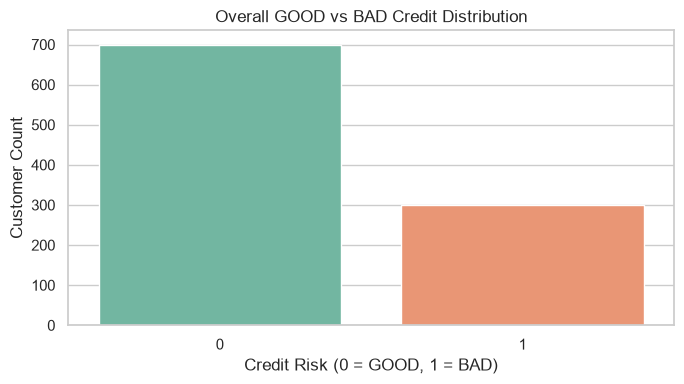

Detected Numerical Features: ['credit_amount', 'installment_rate', 'age', 'existing_credits', 'people_liable']
Total Numerical Features: 5


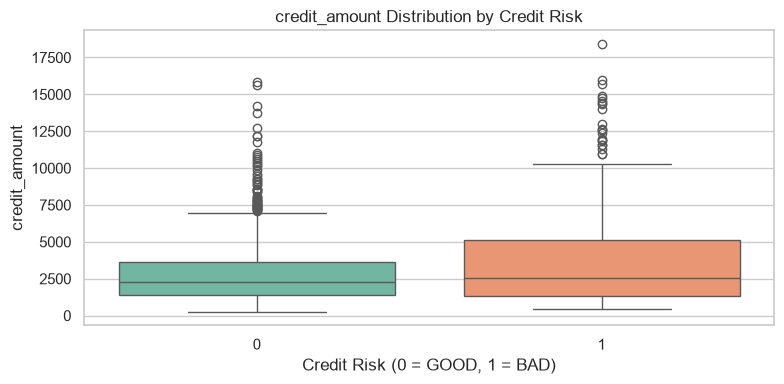

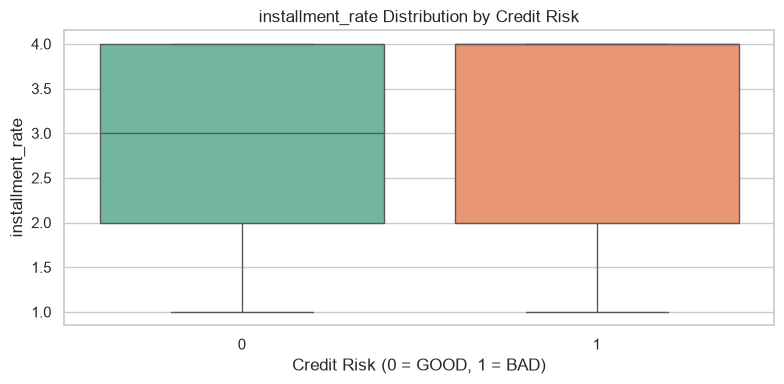

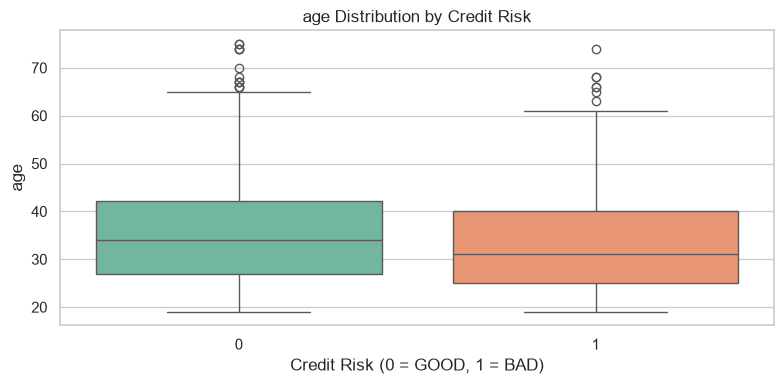

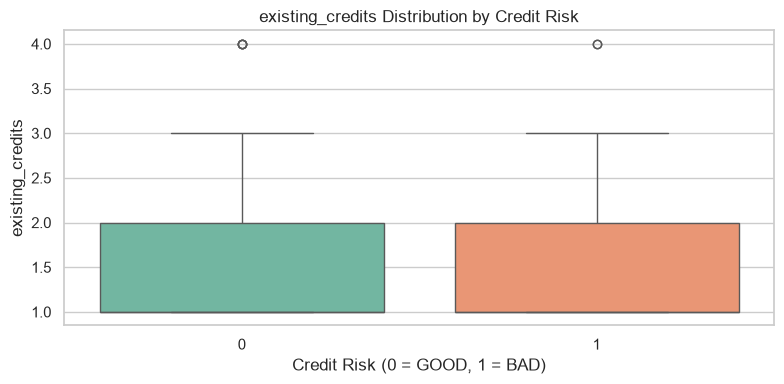

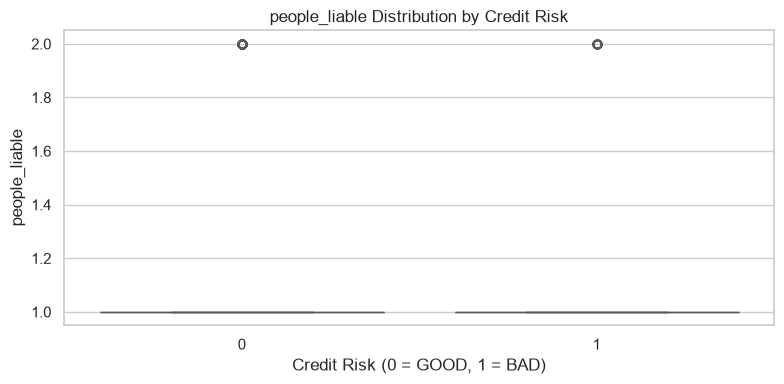


NUMERICAL FEATURES: DEFAULT RATE ANALYSIS

Default Rate Analysis: credit_amount


,Customer_Count,Bad_Credit_Rate
Feature_Group,,
"(249.999, 1365.5]",250,30.8
"(1365.5, 2319.5]",250,24.8
"(2319.5, 3972.25]",250,22.4
"(3972.25, 18424.0]",250,42.0


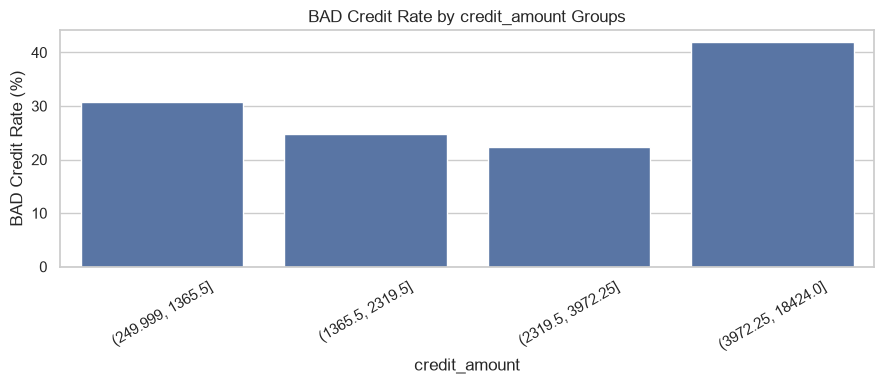


Default Rate Analysis: installment_rate


,Customer_Count,Bad_Credit_Rate
Feature_Group,,
"(0.999, 2.0]",367,26.16
"(2.0, 3.0]",157,28.66
"(3.0, 4.0]",476,33.40


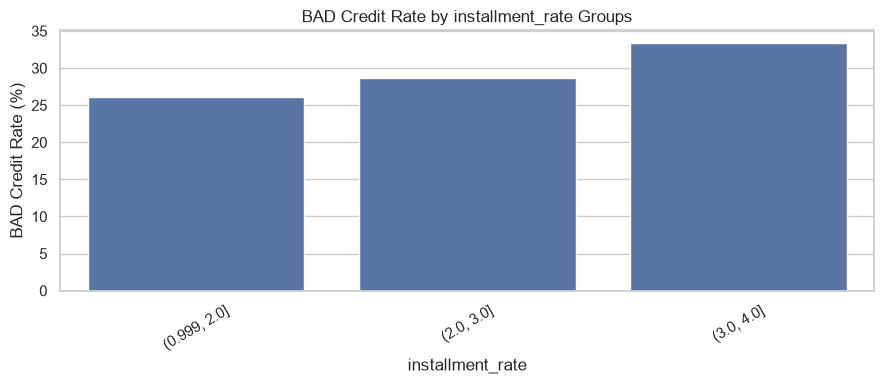


Default Rate Analysis: age


,Customer_Count,Bad_Credit_Rate
Feature_Group,,
"(18.999, 27.0]",291,36.77
"(27.0, 33.0]",225,32.89
"(33.0, 42.0]",249,23.69
"(42.0, 75.0]",235,25.53


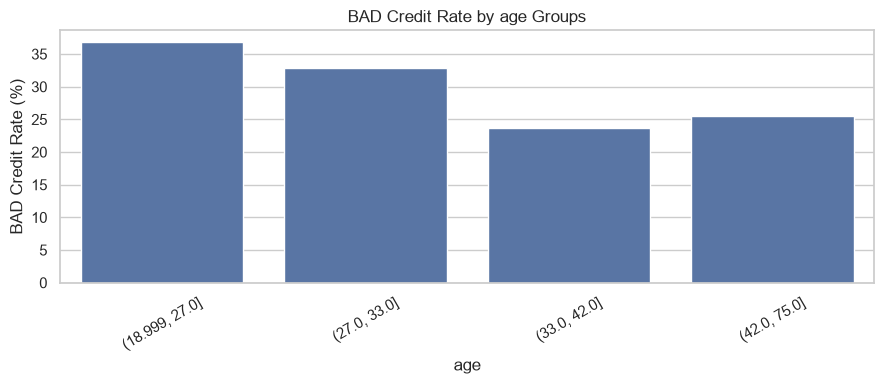


Default Rate Analysis: existing_credits


,Customer_Count,Bad_Credit_Rate
Feature_Group,,
"(0.999, 2.0]",966,30.23
"(2.0, 4.0]",34,23.53


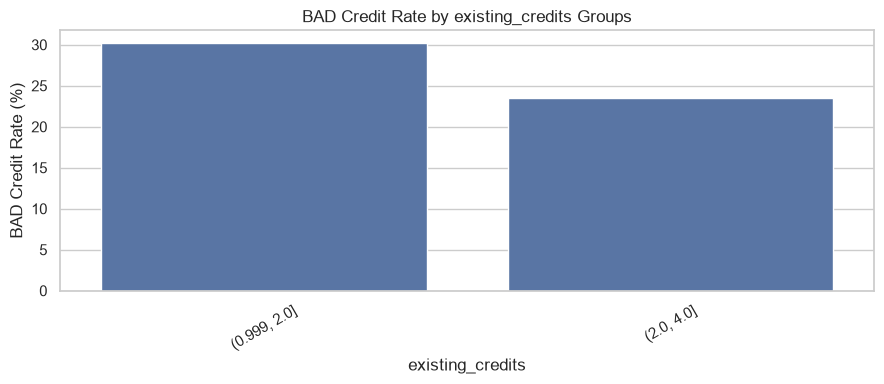


Default Rate Analysis: people_liable


,Customer_Count,Bad_Credit_Rate
Feature_Group,,
"(0.999, 2.0]",1000,30.0


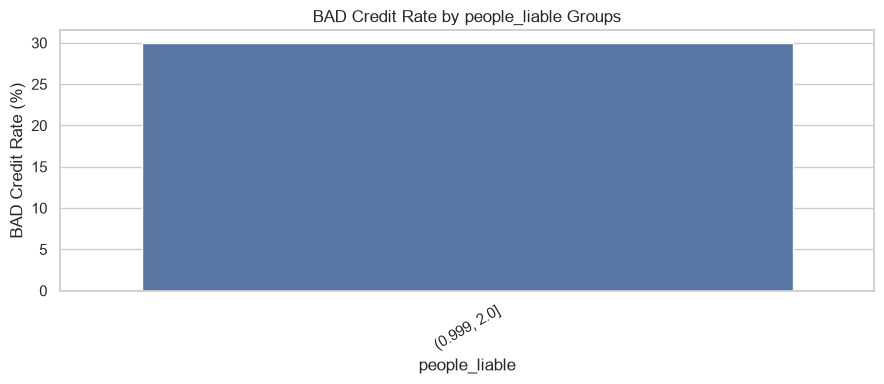


CATEGORICAL FEATURES VS CREDIT RISK

Credit Risk Analysis: checking_account


,Customer_Count,Bad_Credit_Rate
checking_account,,
A11,274,49.27
A12,269,39.03
A13,63,22.22
A14,394,11.68


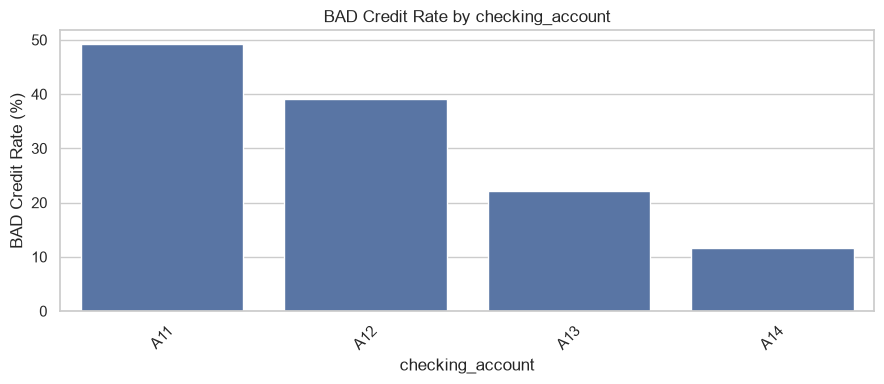


Credit Risk Analysis: credit_history


,Customer_Count,Bad_Credit_Rate
credit_history,,
A30,40,62.50
A31,49,57.14
A32,530,31.89
A33,88,31.82
A34,293,17.06


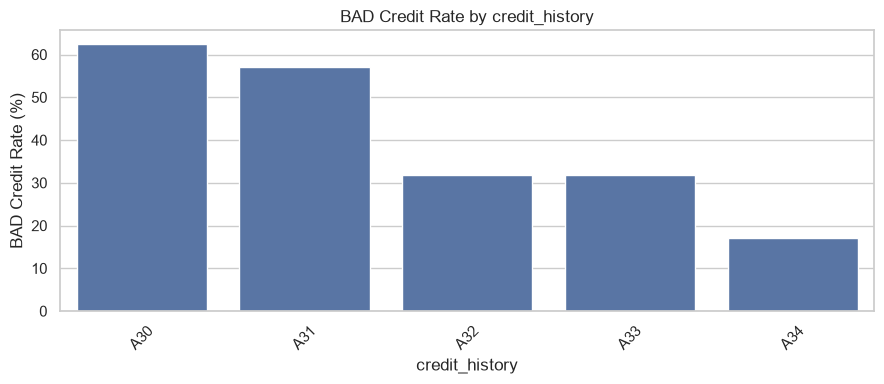


Credit Risk Analysis: purpose


,Customer_Count,Bad_Credit_Rate
purpose,,
A40,234,38.03
A41,103,16.50
A410,12,41.67
A42,181,32.04
A43,280,22.14
A44,12,33.33
A45,22,36.36
A46,50,44.00
A48,9,11.11


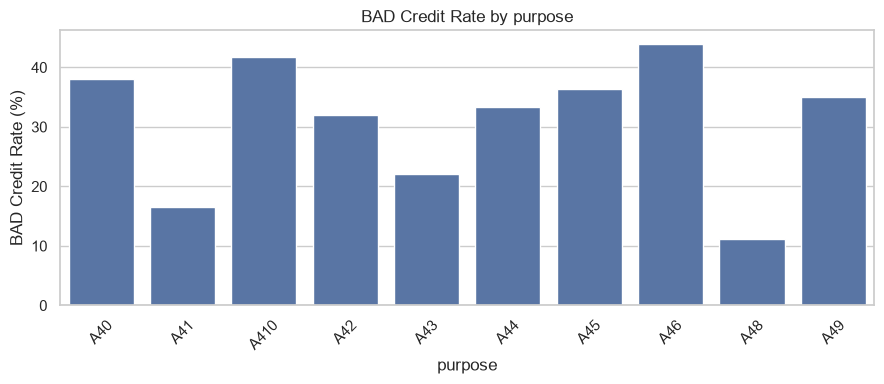


Credit Risk Analysis: savings_account


,Customer_Count,Bad_Credit_Rate
savings_account,,
A61,603,35.99
A62,103,33.01
A63,63,17.46
A64,48,12.50
A65,183,17.49


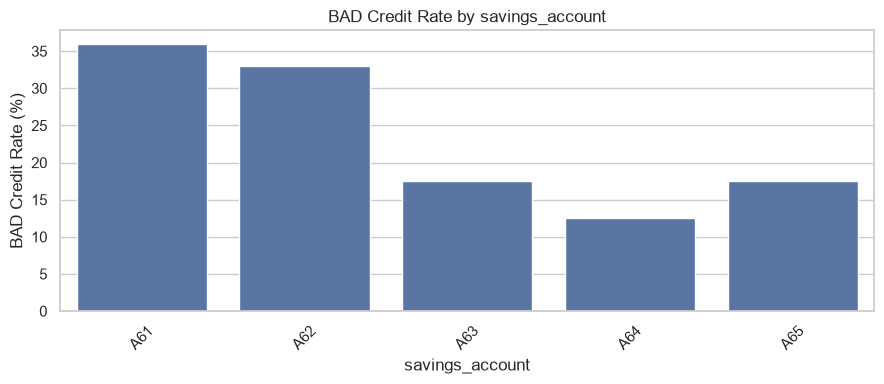


Credit Risk Analysis: employment_duration


,Customer_Count,Bad_Credit_Rate
employment_duration,,
A71,62,37.10
A72,172,40.70
A73,339,30.68
A74,174,22.41
A75,253,25.30


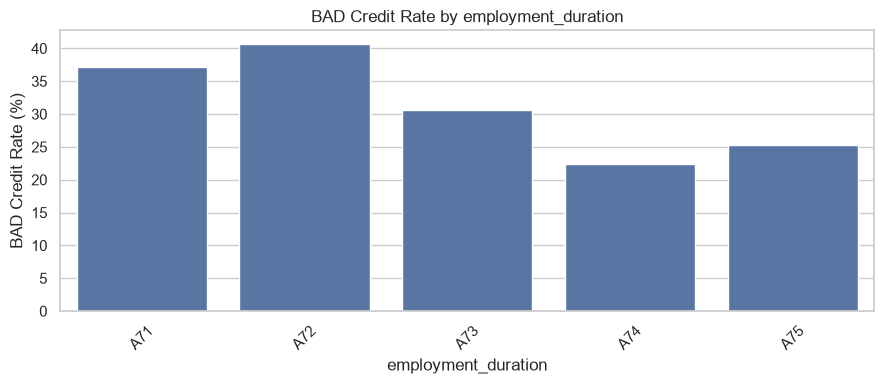


Credit Risk Analysis: personal_status_sex


,Customer_Count,Bad_Credit_Rate
personal_status_sex,,
A91,50,40.00
A92,310,35.16
A93,548,26.64
A94,92,27.17


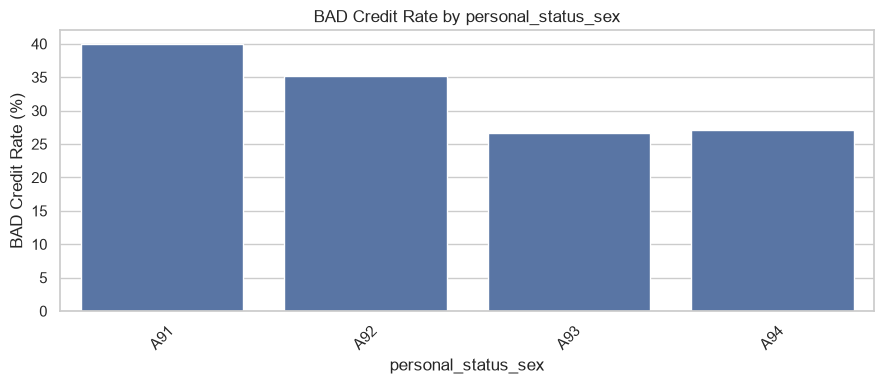


Credit Risk Analysis: other_debtors


,Customer_Count,Bad_Credit_Rate
other_debtors,,
A101,907,29.99
A102,41,43.90
A103,52,19.23


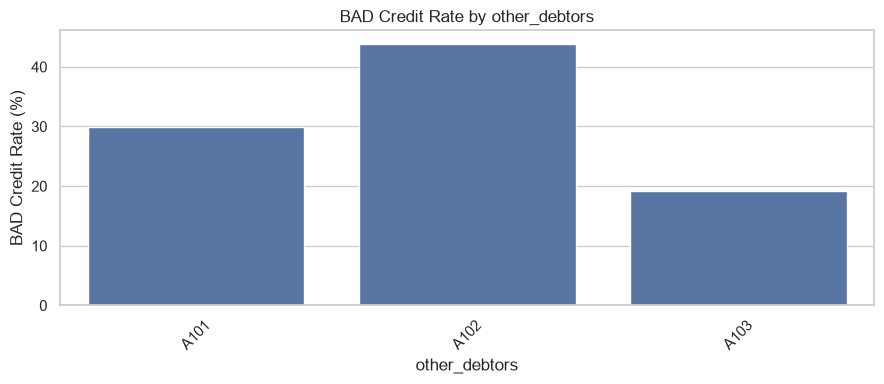


Credit Risk Analysis: property


,Customer_Count,Bad_Credit_Rate
property,,
A121,282,21.28
A122,232,30.60
A123,332,30.72
A124,154,43.51


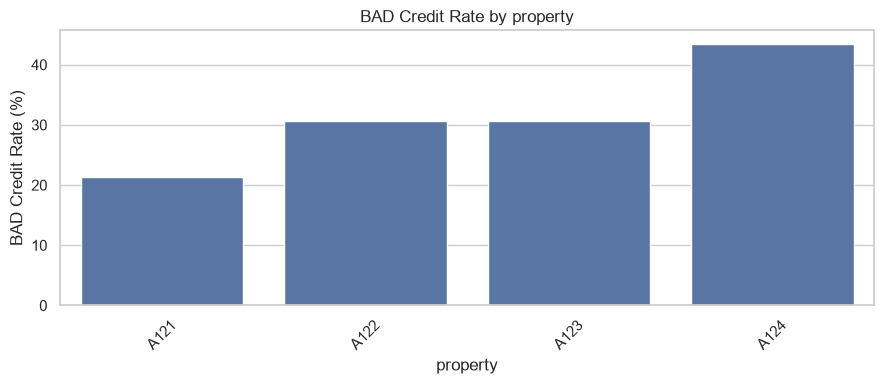


Credit Risk Analysis: other_installment_plans


,Customer_Count,Bad_Credit_Rate
other_installment_plans,,
A141,139,41.01
A142,47,40.43
A143,814,27.52


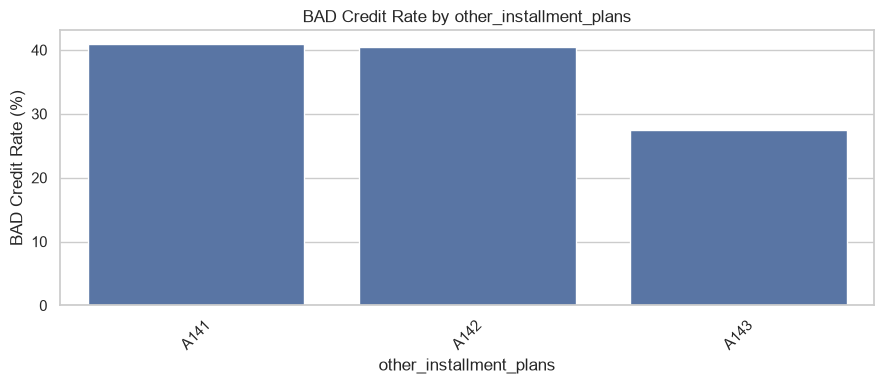


Credit Risk Analysis: housing


,Customer_Count,Bad_Credit_Rate
housing,,
A151,179,39.11
A152,713,26.09
A153,108,40.74


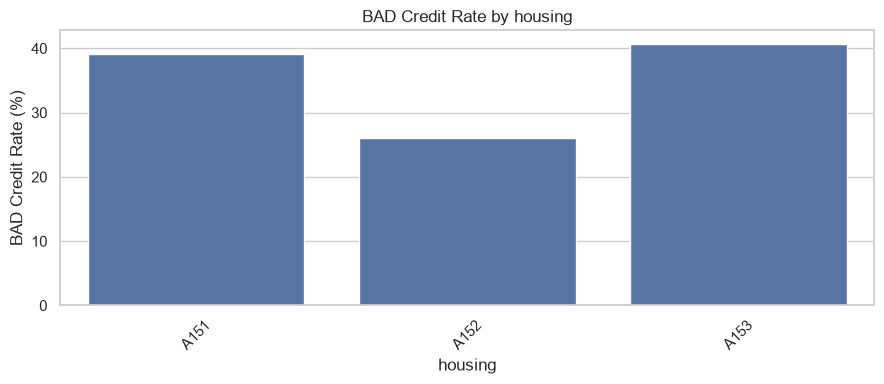


Credit Risk Analysis: job


,Customer_Count,Bad_Credit_Rate
job,,
A171,22,31.82
A172,200,28.00
A173,630,29.52
A174,148,34.46


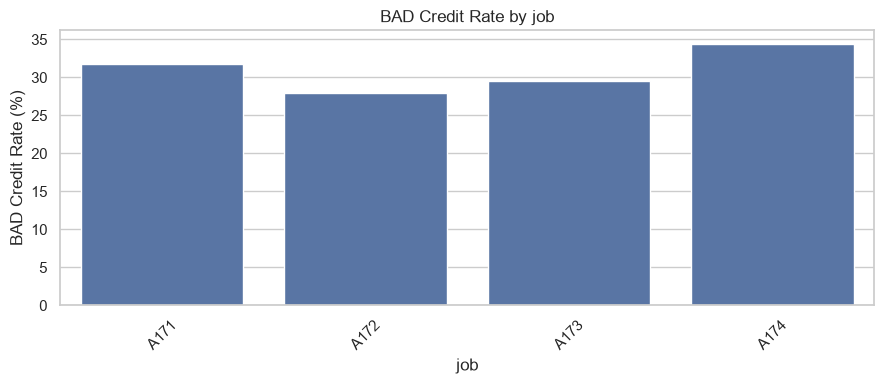


Credit Risk Analysis: telephone


,Customer_Count,Bad_Credit_Rate
telephone,,
A191,596,31.38
A192,404,27.97


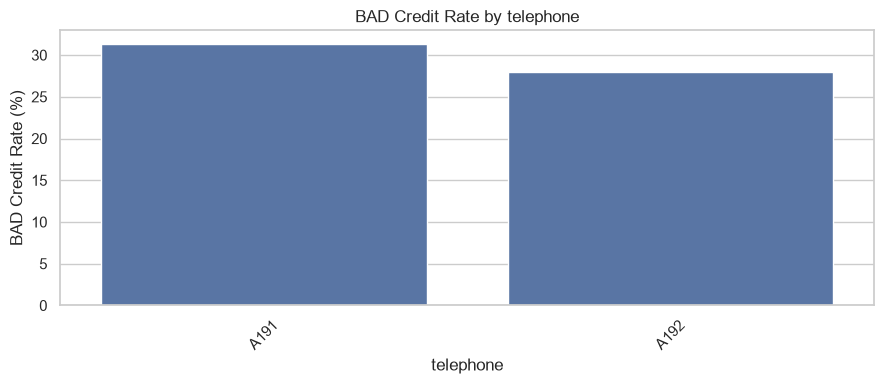


Credit Risk Analysis: foreign_worker


,Customer_Count,Bad_Credit_Rate
foreign_worker,,
A201,963,30.74
A202,37,10.81


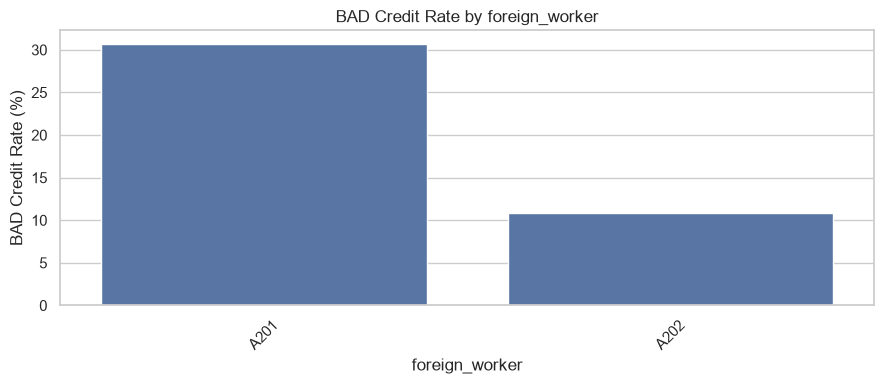


CATEGORICAL FEATURES: GOOD VS BAD COMPARISON

GOOD vs BAD Distribution: checking_account


credit_risk,GOOD (%),BAD (%)
checking_account,,
A11,50.73,49.27
A12,60.97,39.03
A13,77.78,22.22
A14,88.32,11.68


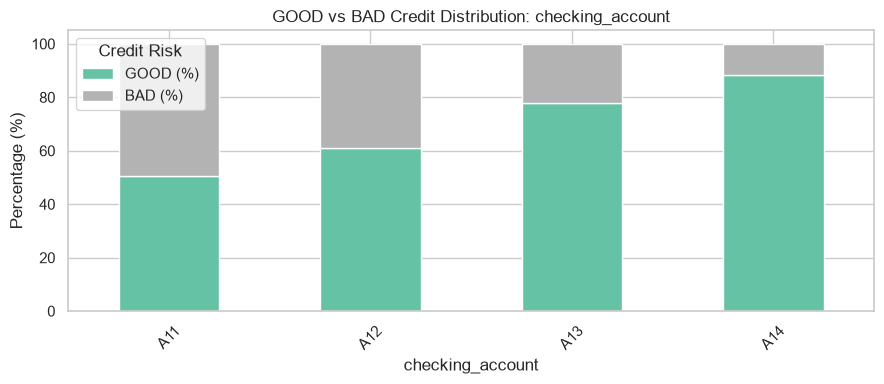


GOOD vs BAD Distribution: credit_history


credit_risk,GOOD (%),BAD (%)
credit_history,,
A30,37.50,62.50
A31,42.86,57.14
A32,68.11,31.89
A33,68.18,31.82
A34,82.94,17.06


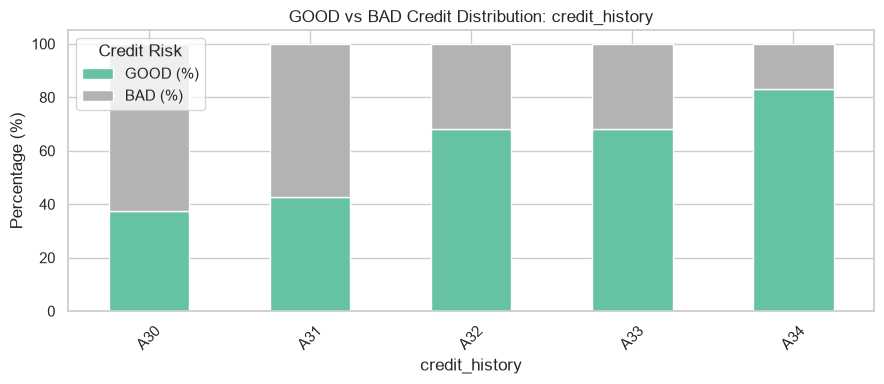


GOOD vs BAD Distribution: purpose


credit_risk,GOOD (%),BAD (%)
purpose,,
A40,61.97,38.03
A41,83.50,16.50
A410,58.33,41.67
A42,67.96,32.04
A43,77.86,22.14
A44,66.67,33.33
A45,63.64,36.36
A46,56.00,44.00
A48,88.89,11.11


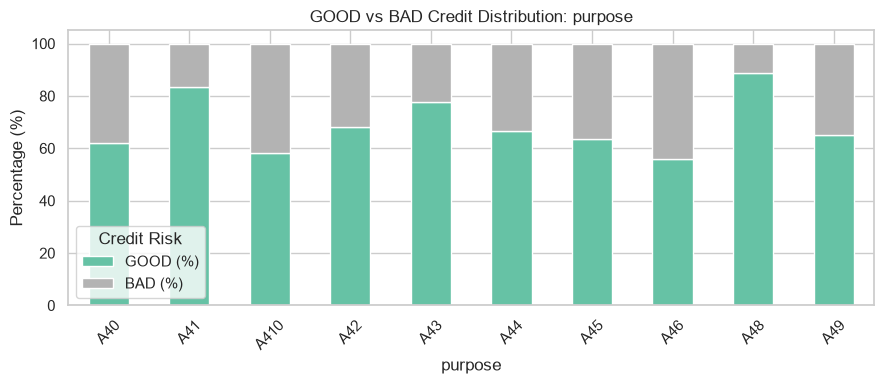


GOOD vs BAD Distribution: savings_account


credit_risk,GOOD (%),BAD (%)
savings_account,,
A61,64.01,35.99
A62,66.99,33.01
A63,82.54,17.46
A64,87.50,12.50
A65,82.51,17.49


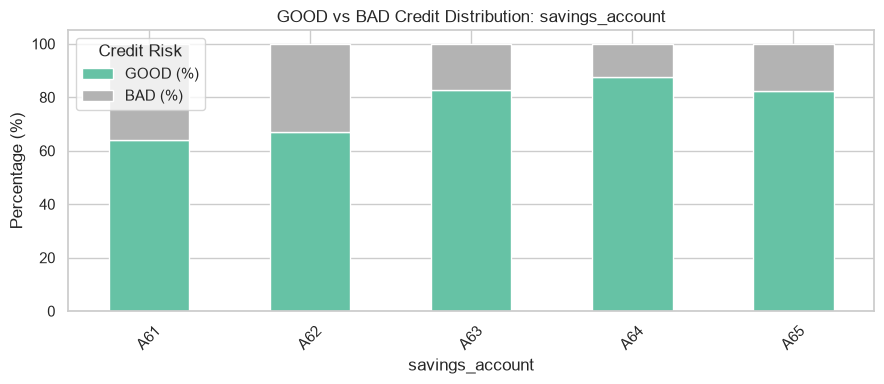


GOOD vs BAD Distribution: employment_duration


credit_risk,GOOD (%),BAD (%)
employment_duration,,
A71,62.90,37.10
A72,59.30,40.70
A73,69.32,30.68
A74,77.59,22.41
A75,74.70,25.30


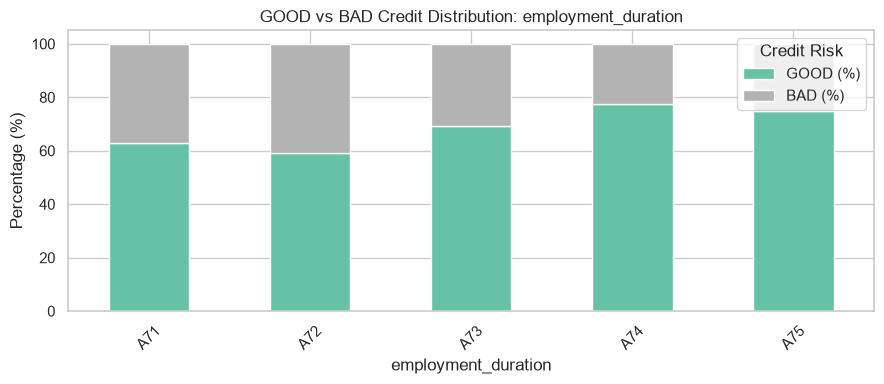


GOOD vs BAD Distribution: personal_status_sex


credit_risk,GOOD (%),BAD (%)
personal_status_sex,,
A91,60.00,40.00
A92,64.84,35.16
A93,73.36,26.64
A94,72.83,27.17


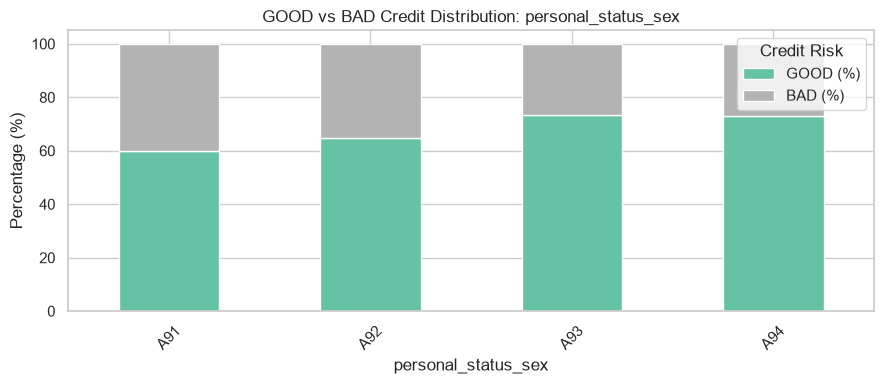


GOOD vs BAD Distribution: other_debtors


credit_risk,GOOD (%),BAD (%)
other_debtors,,
A101,70.01,29.99
A102,56.10,43.90
A103,80.77,19.23


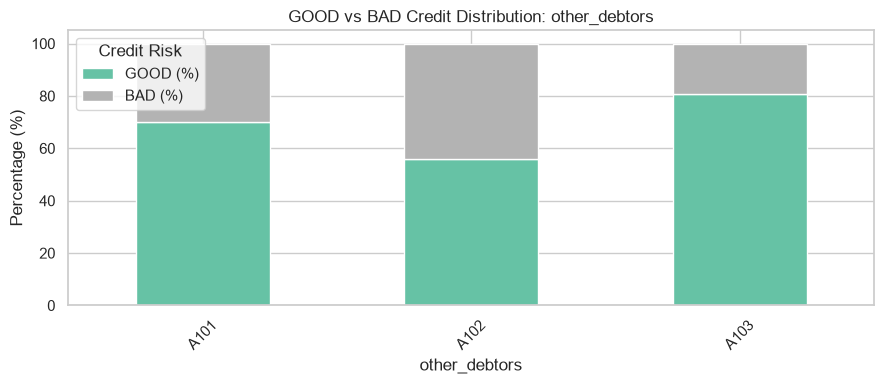


GOOD vs BAD Distribution: property


credit_risk,GOOD (%),BAD (%)
property,,
A121,78.72,21.28
A122,69.40,30.60
A123,69.28,30.72
A124,56.49,43.51


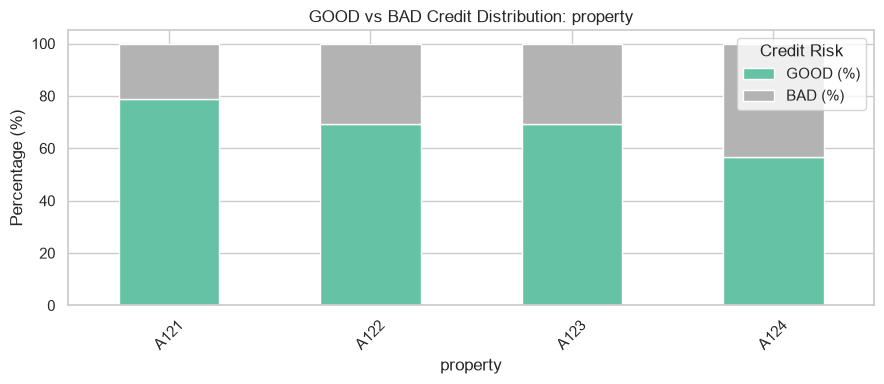


GOOD vs BAD Distribution: other_installment_plans


credit_risk,GOOD (%),BAD (%)
other_installment_plans,,
A141,58.99,41.01
A142,59.57,40.43
A143,72.48,27.52


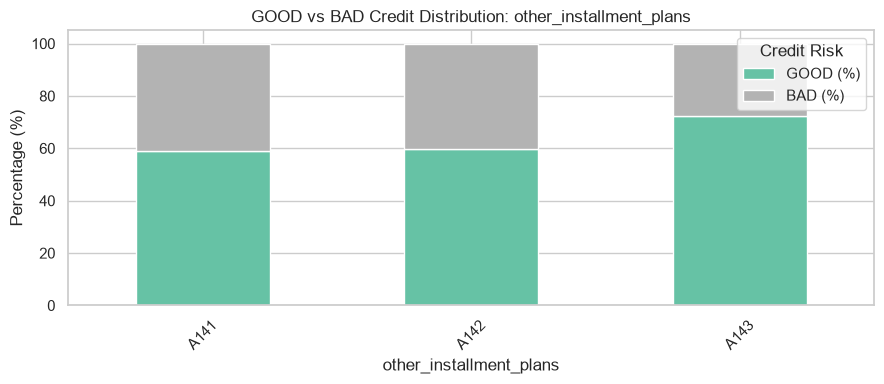


GOOD vs BAD Distribution: housing


credit_risk,GOOD (%),BAD (%)
housing,,
A151,60.89,39.11
A152,73.91,26.09
A153,59.26,40.74


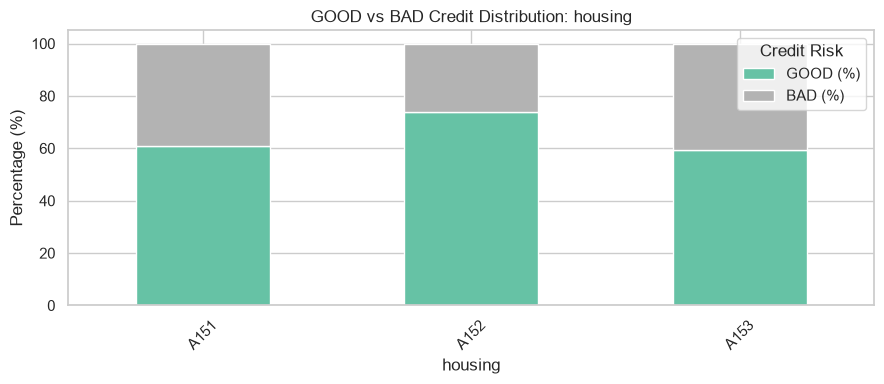


GOOD vs BAD Distribution: job


credit_risk,GOOD (%),BAD (%)
job,,
A171,68.18,31.82
A172,72.00,28.00
A173,70.48,29.52
A174,65.54,34.46


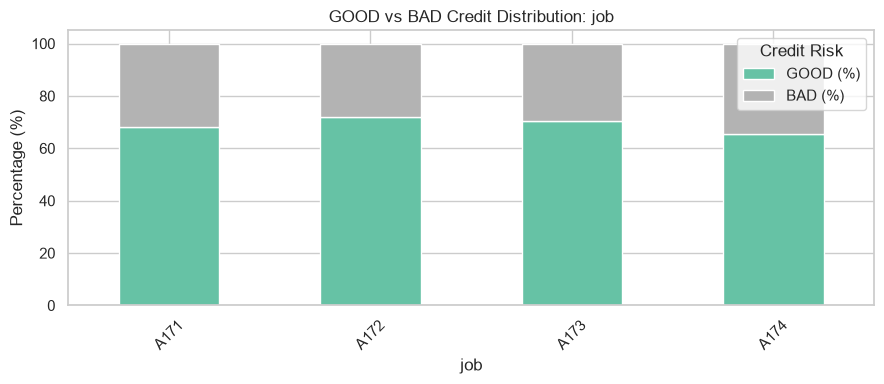


GOOD vs BAD Distribution: telephone


credit_risk,GOOD (%),BAD (%)
telephone,,
A191,68.62,31.38
A192,72.03,27.97


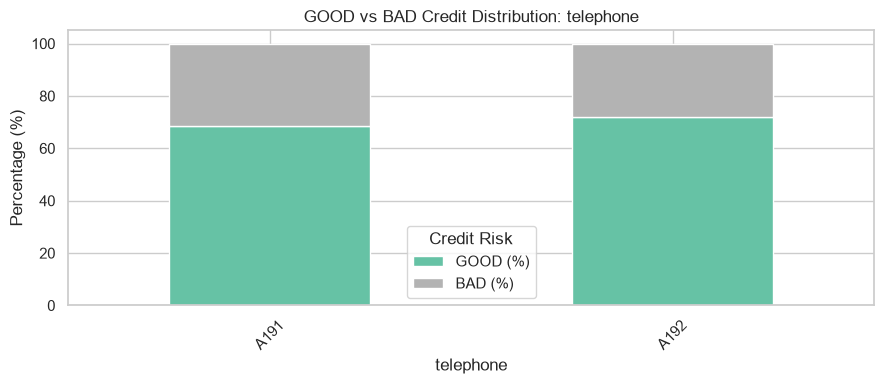


GOOD vs BAD Distribution: foreign_worker


credit_risk,GOOD (%),BAD (%)
foreign_worker,,
A201,69.26,30.74
A202,89.19,10.81


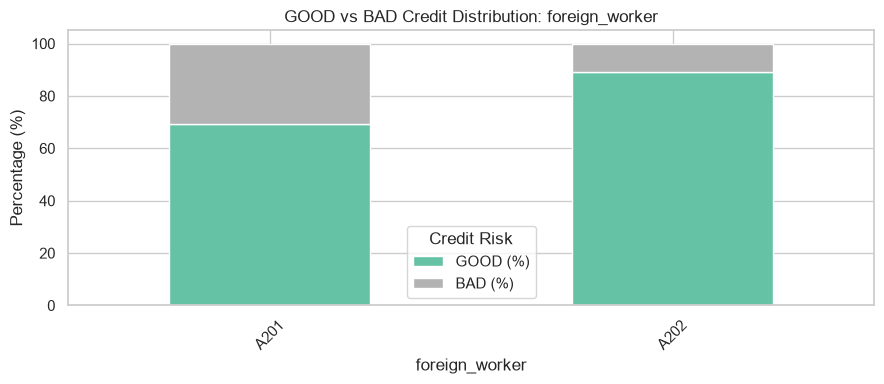


SPECIAL CATEGORY RISK ANALYSIS

Feature: savings_account
Category: A65
Customer Count: 183


,Customer_Count,Percentage
credit_risk,,
0,151,82.51
1,32,17.49



Feature: property
Category: A124
Customer Count: 154


,Customer_Count,Percentage
credit_risk,,
0,87,56.49
1,67,43.51



NUMERICAL FEATURE CORRELATION WITH CREDIT RISK

Correlation with BAD Credit Risk:


,Correlation
credit_amount,0.155
installment_rate,0.072
people_liable,-0.003
existing_credits,-0.046
age,-0.091


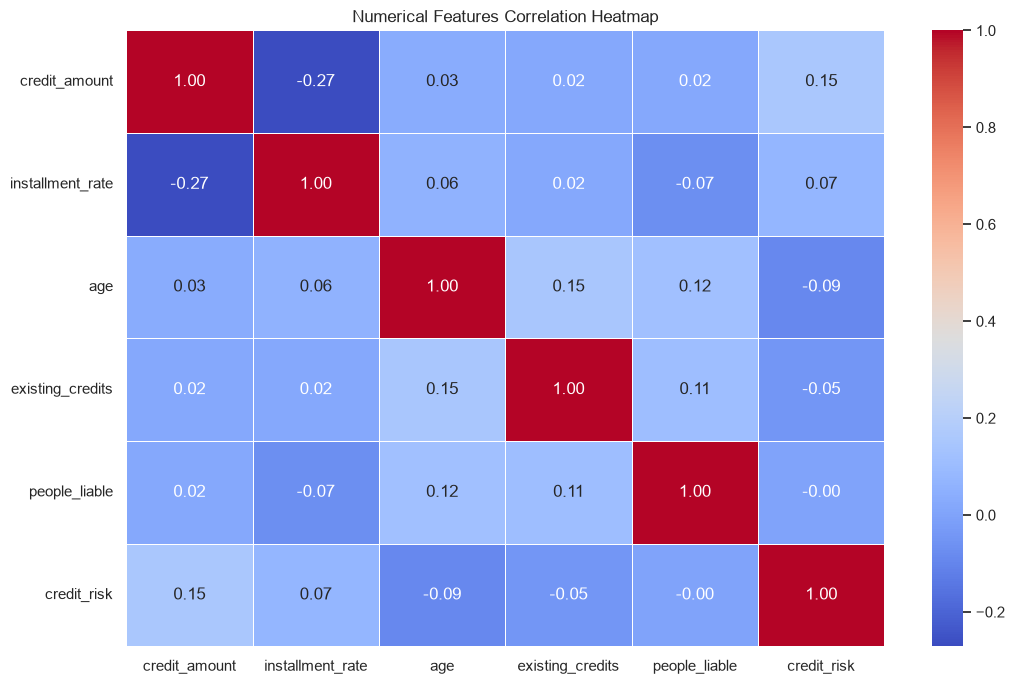


HIGHER AND LOWER RISK CATEGORIES

Feature: checking_account
Higher observed BAD rate: A11 - 49.27 %
Lower observed BAD rate: A14 - 11.68 %

Feature: credit_history
Higher observed BAD rate: A30 - 62.5 %
Lower observed BAD rate: A34 - 17.06 %

Feature: purpose
Higher observed BAD rate: A46 - 44.0 %
Lower observed BAD rate: A41 - 16.5 %

Feature: savings_account
Higher observed BAD rate: A61 - 35.99 %
Lower observed BAD rate: A64 - 12.5 %

Feature: employment_duration
Higher observed BAD rate: A72 - 40.7 %
Lower observed BAD rate: A74 - 22.41 %

Feature: personal_status_sex
Higher observed BAD rate: A91 - 40.0 %
Lower observed BAD rate: A93 - 26.64 %

Feature: other_debtors
Higher observed BAD rate: A102 - 43.9 %
Lower observed BAD rate: A103 - 19.23 %

Feature: property
Higher observed BAD rate: A124 - 43.51 %
Lower observed BAD rate: A121 - 21.28 %

Feature: other_installment_plans
Higher observed BAD rate: A141 - 41.01 %
Lower observed BAD rate: A143 - 27.52 %

Feature: housing
Highe

In [5]:

# ============================================================
# SECTION 5: BIVARIATE RISK ANALYSIS
# FEATURE RELATIONSHIPS WITH DEFAULT STATUS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# 1. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

numerical_cols = [
    "duration",
    "credit_amount",
    "installment_rate",
    "present_residence",
    "age",
    "existing_credits",
    "people_liable"
]

categorical_cols = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_duration",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

target_col = "credit_risk"

print("BIVARIATE RISK ANALYSIS")
print("=" * 60)

print("Numerical Features:", len(numerical_cols))
print("Categorical Features:", len(categorical_cols))
print("Target Variable:", target_col)


# 2. VERIFY TARGET VARIABLE

print("\nTARGET VARIABLE VERIFICATION")
print("=" * 60)

print(df[target_col].value_counts())

assert target_col in df.columns
assert set(df[target_col].dropna().unique()).issubset({0, 1})

print("\nTarget verification completed.")
print("0 = GOOD CREDIT")
print("1 = BAD CREDIT")


# 3. OVERALL CREDIT RISK DISTRIBUTION

print("\nOVERALL CREDIT RISK DISTRIBUTION")
print("=" * 60)

risk_distribution = (
    df[target_col]
    .value_counts()
    .sort_index()
)

risk_percentage = (
    df[target_col]
    .value_counts(normalize=True)
    .sort_index() * 100
)

risk_summary = pd.DataFrame({
    "Customer_Count": risk_distribution,
    "Percentage": risk_percentage
})

display(risk_summary.round(2))

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x=target_col,
    hue=target_col,
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.title("Overall GOOD vs BAD Credit Distribution")
plt.xlabel("Credit Risk (0 = GOOD, 1 = BAD)")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

# 4. NUMERICAL FEATURES VS CREDIT RISK


# NUMERICAL FEATURES - AUTOMATIC COLUMN DETECTION

numerical_candidates = [
    "duration",
    "duration_in_month",
    "credit_amount",
    "installment_rate",
    "present_residence",
    "present_residence_since",
    "age",
    "existing_credits",
    "people_liable",
    "number_of_existing_credits",
    "number_of_people_liable"
]

numerical_cols = [
    col for col in numerical_candidates
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

print("Detected Numerical Features:", numerical_cols)
print("Total Numerical Features:", len(numerical_cols))

if not numerical_cols:
    raise ValueError(
        "No numerical features detected. "
        "Check the column names and data types in Section 1."
    )




# 5. NUMERICAL FEATURE DISTRIBUTION BY CREDIT RISK

for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=target_col,
        y=col,
        hue=target_col,
        palette="Set2",
        legend=False
    )

    plt.title(f"{col} Distribution by Credit Risk")
    plt.xlabel("Credit Risk (0 = GOOD, 1 = BAD)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


# 6. NUMERICAL FEATURES: DEFAULT RATE ANALYSIS

print("\nNUMERICAL FEATURES: DEFAULT RATE ANALYSIS")
print("=" * 60)

for col in numerical_cols:

    analysis_df = df[[col, target_col]].copy()

    analysis_df["Feature_Group"] = pd.qcut(
        analysis_df[col],
        q=4,
        duplicates="drop"
    )

    risk_table = (
        analysis_df.groupby(
            "Feature_Group",
            observed=True
        )[target_col]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    risk_table["Bad_Credit_Rate"] *= 100

    print(f"\nDefault Rate Analysis: {col}")

    display(risk_table.round(2))

    plot_data = risk_table.reset_index()

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=plot_data,
        x="Feature_Group",
        y="Bad_Credit_Rate"
    )

    plt.title(f"BAD Credit Rate by {col} Groups")
    plt.xlabel(col)
    plt.ylabel("BAD Credit Rate (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


# 7. CATEGORICAL FEATURES VS CREDIT RISK

print("\nCATEGORICAL FEATURES VS CREDIT RISK")
print("=" * 60)

for col in categorical_cols:

    risk_table = (
        df.groupby(col, observed=True)[target_col]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    risk_table["Bad_Credit_Rate"] *= 100

    print(f"\nCredit Risk Analysis: {col}")

    display(risk_table.round(2))

    plot_data = risk_table.reset_index()

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=plot_data,
        x=col,
        y="Bad_Credit_Rate"
    )

    plt.title(f"BAD Credit Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("BAD Credit Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 8. CATEGORICAL FEATURES: GOOD VS BAD COMPARISON

print("\nCATEGORICAL FEATURES: GOOD VS BAD COMPARISON")
print("=" * 60)

for col in categorical_cols:

    comparison = pd.crosstab(
        df[col],
        df[target_col],
        normalize="index"
    ) * 100

    comparison = comparison.rename(columns={
        0: "GOOD (%)",
        1: "BAD (%)"
    })

    print(f"\nGOOD vs BAD Distribution: {col}")

    display(comparison.round(2))

    comparison.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 4),
        colormap="Set2"
    )

    plt.title(f"GOOD vs BAD Credit Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=45)
    plt.legend(title="Credit Risk")
    plt.tight_layout()
    plt.show()


# 9. SPECIAL CATEGORY RISK ANALYSIS: A65 AND A124

print("\nSPECIAL CATEGORY RISK ANALYSIS")
print("=" * 60)

special_categories = {
    "savings_account": "A65",
    "property": "A124"
}

for col, category in special_categories.items():

    special_df = df[df[col] == category]

    print(f"\nFeature: {col}")
    print(f"Category: {category}")
    print("Customer Count:", len(special_df))

    if len(special_df) > 0:

        special_risk = (
            special_df[target_col]
            .value_counts()
            .sort_index()
        )

        special_percentage = (
            special_df[target_col]
            .value_counts(normalize=True)
            .sort_index() * 100
        )

        special_summary = pd.DataFrame({
            "Customer_Count": special_risk,
            "Percentage": special_percentage
        })

        display(special_summary.round(2))


# 10. CORRELATION ANALYSIS WITH CREDIT RISK

print("\nNUMERICAL FEATURE CORRELATION WITH CREDIT RISK")
print("=" * 60)

correlation_data = df[
    numerical_cols + [target_col]
].corr(numeric_only=True)

target_correlation = (
    correlation_data[target_col]
    .drop(target_col)
    .sort_values(ascending=False)
)

print("\nCorrelation with BAD Credit Risk:")

display(target_correlation.to_frame(
    name="Correlation"
).round(3))


# 11. CORRELATION HEATMAP

plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()


# 12. IDENTIFY HIGHER AND LOWER RISK CATEGORIES

print("\nHIGHER AND LOWER RISK CATEGORIES")
print("=" * 60)

for col in categorical_cols:

    risk_table = (
        df.groupby(col, observed=True)[target_col]
        .agg(["count", "mean"])
    )

    risk_table["mean"] *= 100

    risk_table = risk_table.rename(columns={
        "count": "Customer_Count",
        "mean": "Bad_Credit_Rate"
    })

    # Ignore categories with very small sample sizes
    reliable_categories = risk_table[
        risk_table["Customer_Count"] >= 10
    ]

    if not reliable_categories.empty:

        highest_risk = reliable_categories[
            "Bad_Credit_Rate"
        ].idxmax()

        lowest_risk = reliable_categories[
            "Bad_Credit_Rate"
        ].idxmin()

        print(f"\nFeature: {col}")

        print(
            "Higher observed BAD rate:",
            highest_risk,
            "-",
            round(
                reliable_categories.loc[
                    highest_risk, "Bad_Credit_Rate"
                ], 2
            ), "%"
        )

        print(
            "Lower observed BAD rate:",
            lowest_risk,
            "-",
            round(
                reliable_categories.loc[
                    lowest_risk, "Bad_Credit_Rate"
                ], 2
            ), "%"
        )


# 13. DOMAIN INTERPRETATION

print("\nDOMAIN INTERPRETATION")
print("=" * 60)

print("1. Bivariate analysis examines the relationship between")
print("   individual features and credit default status.")

print("2. Numerical feature comparisons help identify differences")
print("   between GOOD and BAD credit customers.")

print("3. Categorical risk analysis identifies categories with")
print("   different observed BAD credit rates.")

print("4. Higher BAD credit rates indicate greater observed")
print("   default frequency within a category.")

print("5. A65 and A124 are retained as valid categorical values.")

print("6. Correlation analysis measures linear relationships")
print("   between numerical features and the binary target.")

print("7. Correlation does not establish causation.")

print("8. Small category sample sizes should be considered")
print("   before interpreting risk percentages.")


# 14. FINAL VALIDATION

print("\nFINAL VALIDATION")
print("=" * 60)

# Check numerical features
print("Numerical Features Detected:", len(numerical_cols))
print("Numerical Columns:", numerical_cols)

# Check categorical features
print("Categorical Features Detected:", len(categorical_cols))

# Check target variable
assert target_col in df.columns, "Target column is missing."
assert df[target_col].notna().all(), "Target contains missing values."
assert set(df[target_col].unique()).issubset({0, 1}), \
    "Target must contain only 0 and 1."

# Check feature columns
assert len(numerical_cols) > 0, "No numerical features detected."
assert len(categorical_cols) > 0, "No categorical features detected."

assert all(col in df.columns for col in numerical_cols)
assert all(col in df.columns for col in categorical_cols)

print("\nNumerical Feature Analysis: Completed")
print("Categorical Feature Analysis: Completed")
print("GOOD vs BAD Comparison: Completed")
print("Default Rate Analysis: Completed")
print("A65 Risk Analysis: Completed")
print("A124 Risk Analysis: Completed")
print("Correlation Analysis: Completed")
print("Domain Interpretation: Completed")

print("\n==============================================")
print("SECTION 5 COMPLETED SUCCESSFULLY")
print("==============================================")



## Section 6: Audit of Protected Attributes (Sex, Age, Foreign Worker)


### Interpretation

*Write your interpretation here.*


PROTECTED ATTRIBUTE AUDIT
Available Protected Attributes: ['personal_status_sex', 'age', 'foreign_worker']

Required columns verified.

SEX / PERSONAL STATUS FREQUENCY AUDIT


,Frequency,Percentage
personal_status_sex,,
A93,548,54.8
A92,310,31.0
A94,92,9.2
A91,50,5.0


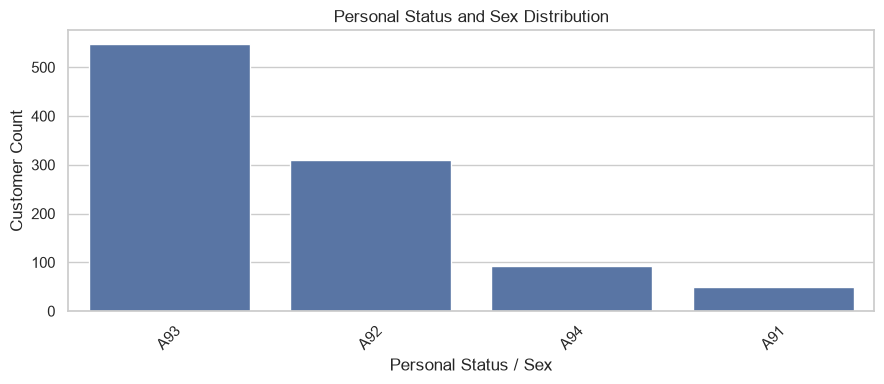


AGE DISTRIBUTION AUDIT
Minimum Age: 19
Maximum Age: 75
Average Age: 35.55
Median Age: 33.0


,Age Statistics
count,1000.00
mean,35.55
std,11.38
min,19.00
25%,27.00
50%,33.00
75%,42.00
max,75.00


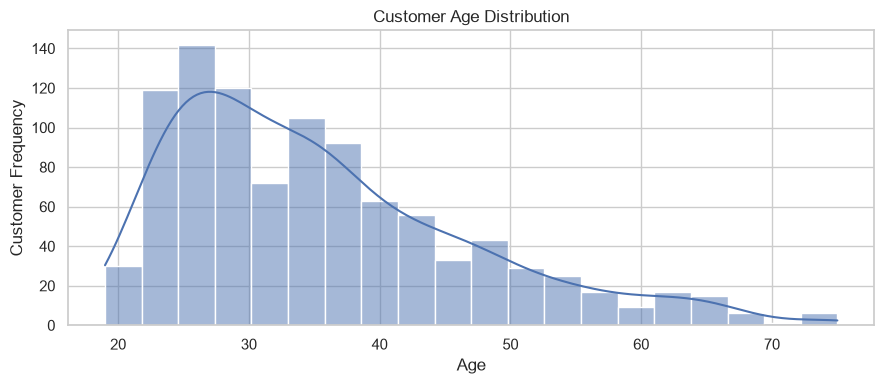


AGE GROUP ANALYSIS


,Customer_Count,Percentage
age_group,,
18-24,149,14.9
25-34,399,39.9
35-44,251,25.1
45-54,122,12.2
55-64,56,5.6
65+,23,2.3


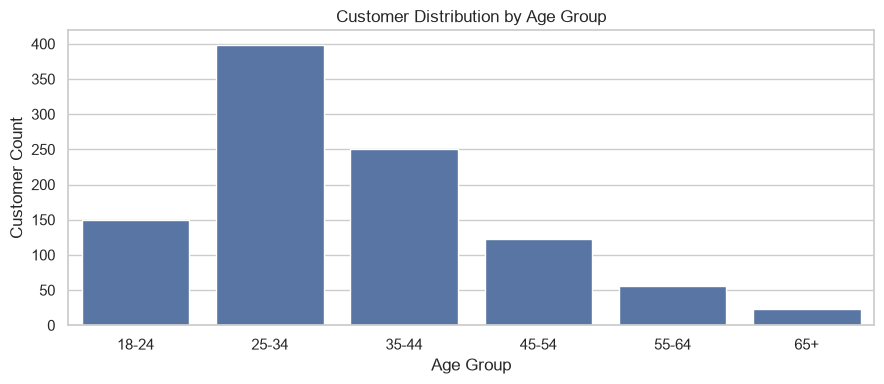


FOREIGN WORKER FREQUENCY AUDIT


,Frequency,Percentage
foreign_worker,,
A201,963,96.3
A202,37,3.7


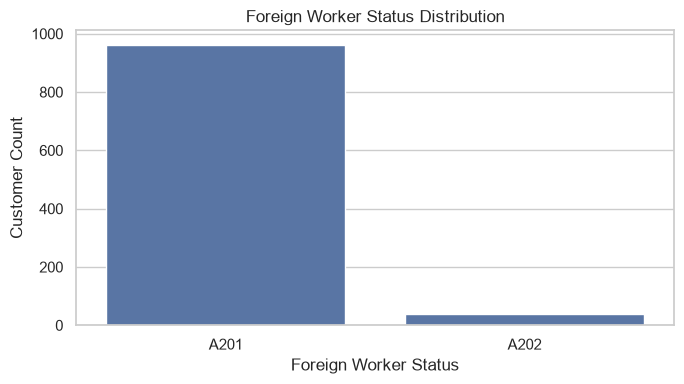


AGE VS CREDIT RISK


,count,mean,median,std
credit_risk,,,,
0,700,36.22,34.0,11.38
1,300,33.96,31.0,11.22


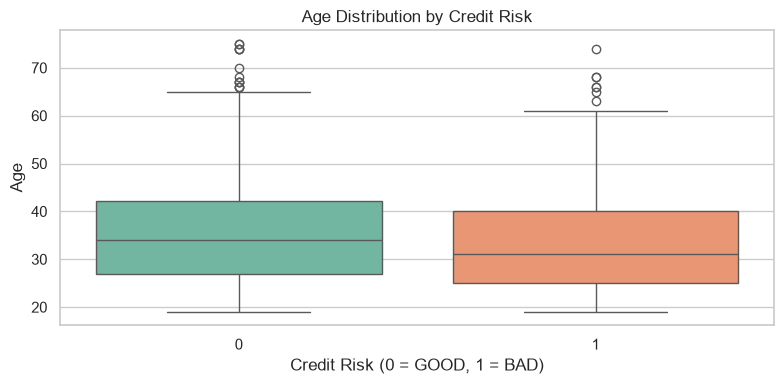


AGE GROUP VS BAD CREDIT RATE


,Customer_Count,Bad_Credit_Rate
age_group,,
18-24,149,40.94
25-34,399,32.83
35-44,251,23.11
45-54,122,22.95
55-64,56,28.57
65+,23,26.09


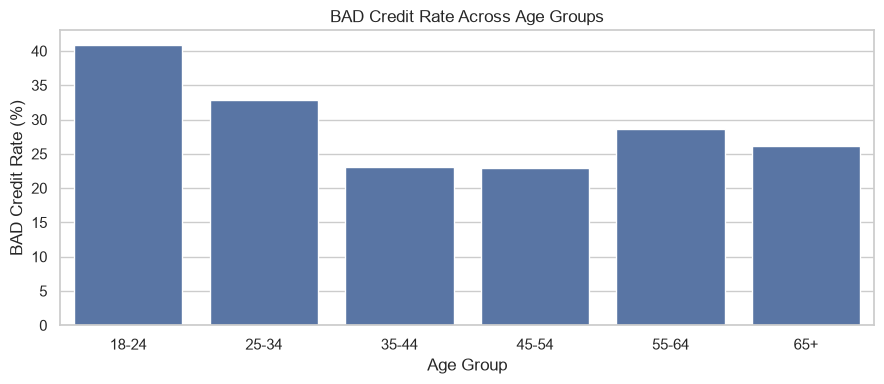


PERSONAL STATUS / SEX VS CREDIT RISK


,Customer_Count,Bad_Credit_Rate
personal_status_sex,,
A91,50,40.00
A92,310,35.16
A93,548,26.64
A94,92,27.17


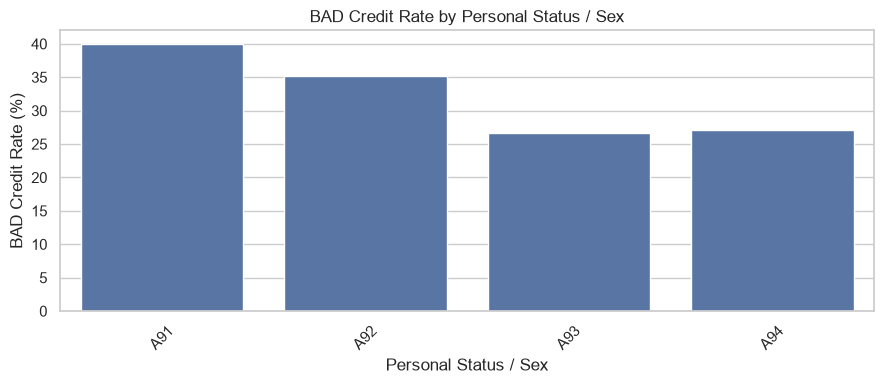


FOREIGN WORKER STATUS VS CREDIT RISK


,Customer_Count,Bad_Credit_Rate
foreign_worker,,
A201,963,30.74
A202,37,10.81


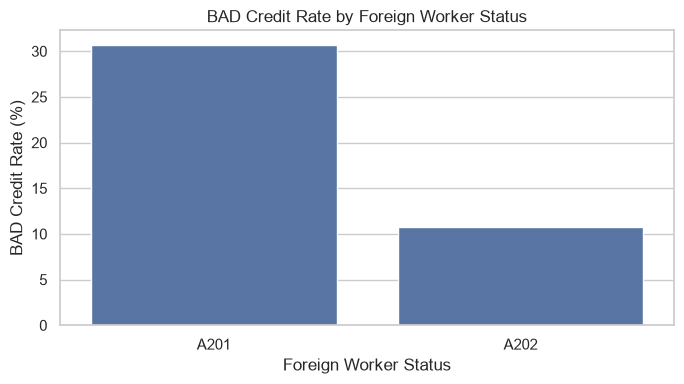


PROTECTED ATTRIBUTE MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
personal_status_sex,0,0.0
age,0,0.0
foreign_worker,0,0.0



DOMAIN INTERPRETATION
1. Age represents the customer's age in years.
2. Personal status and sex provide demographic information.
3. Foreign worker identifies the customer's foreign-worker status.
4. Age groups help examine differences in observed credit risk.
5. BAD credit rates across demographic categories
   describe patterns in the historical dataset.
6. Differences in group default rates do not establish
   that demographic characteristics cause credit default.
7. Protected attributes should be handled carefully
   when developing credit-risk prediction models.
8. Demographic differences may indicate potential
   fairness concerns and require further investigation.

FINAL VALIDATION
Age Audit: Completed
Personal Status / Sex Audit: Completed
Foreign Worker Audit: Completed
Age Group Analysis: Completed
Credit Risk Comparison: Completed
Missing Value Audit: Completed
Domain Interpretation: Completed

SECTION 6 COMPLETED SUCCESSFULLY


In [6]:

# ============================================================
# SECTION 6: AUDIT OF PROTECTED ATTRIBUTES
# SEX, AGE, FOREIGN WORKER
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# 1. IDENTIFY PROTECTED ATTRIBUTE COLUMNS

protected_cols = [
    "personal_status_sex",
    "age",
    "foreign_worker"
]

print("PROTECTED ATTRIBUTE AUDIT")
print("=" * 60)

# Automatically match available column names
available_protected_cols = [
    col for col in protected_cols
    if col in df.columns
]

print("Available Protected Attributes:",
      available_protected_cols)


# 2. VALIDATE REQUIRED COLUMNS

target_col = "credit_risk"

assert target_col in df.columns, \
    "credit_risk column not found."

if "age" not in df.columns:
    raise KeyError(
        "Age column not found. Check your Section 1 column names."
    )

if not any(
    col in df.columns
    for col in ["personal_status_sex", "foreign_worker"]
):
    raise KeyError(
        "Sex or foreign worker column not found."
    )

print("\nRequired columns verified.")


# 3. SEX / PERSONAL STATUS FREQUENCY AUDIT

print("\nSEX / PERSONAL STATUS FREQUENCY AUDIT")
print("=" * 60)

if "personal_status_sex" in df.columns:

    sex_frequency = df[
        "personal_status_sex"
    ].value_counts(dropna=False)

    sex_percentage = df[
        "personal_status_sex"
    ].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    sex_summary = pd.DataFrame({
        "Frequency": sex_frequency,
        "Percentage": sex_percentage
    })

    display(sex_summary.round(2))

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        x="personal_status_sex",
        order=df["personal_status_sex"].value_counts().index
    )

    plt.title("Personal Status and Sex Distribution")
    plt.xlabel("Personal Status / Sex")
    plt.ylabel("Customer Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 4. AGE DISTRIBUTION AUDIT

print("\nAGE DISTRIBUTION AUDIT")
print("=" * 60)

print("Minimum Age:", df["age"].min())
print("Maximum Age:", df["age"].max())
print("Average Age:", round(df["age"].mean(), 2))
print("Median Age:", df["age"].median())

display(df["age"].describe().to_frame(
    name="Age Statistics"
).round(2))

plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Customer Frequency")
plt.tight_layout()
plt.show()


# 5. AGE GROUP ANALYSIS

print("\nAGE GROUP ANALYSIS")
print("=" * 60)

age_bins = [18, 25, 35, 45, 55, 65, np.inf]

age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_summary = pd.DataFrame({
    "Customer_Count": df["age_group"].value_counts(
        sort=False
    ),
    "Percentage": (
        df["age_group"].value_counts(
            normalize=True,
            sort=False
        ) * 100
    )
})

display(age_group_summary.round(2))

plt.figure(figsize=(9, 4))

sns.countplot(
    data=df,
    x="age_group",
    order=age_labels
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()


# 6. FOREIGN WORKER FREQUENCY AUDIT

print("\nFOREIGN WORKER FREQUENCY AUDIT")
print("=" * 60)

if "foreign_worker" in df.columns:

    foreign_frequency = df[
        "foreign_worker"
    ].value_counts(dropna=False)

    foreign_percentage = df[
        "foreign_worker"
    ].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    foreign_summary = pd.DataFrame({
        "Frequency": foreign_frequency,
        "Percentage": foreign_percentage
    })

    display(foreign_summary.round(2))

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x="foreign_worker"
    )

    plt.title("Foreign Worker Status Distribution")
    plt.xlabel("Foreign Worker Status")
    plt.ylabel("Customer Count")
    plt.tight_layout()
    plt.show()


# 7. AGE VS CREDIT RISK

print("\nAGE VS CREDIT RISK")
print("=" * 60)

age_risk = (
    df.groupby(target_col)["age"]
    .agg(["count", "mean", "median", "std"])
)

display(age_risk.round(2))

plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x=target_col,
    y="age",
    hue=target_col,
    palette="Set2",
    legend=False
)

plt.title("Age Distribution by Credit Risk")
plt.xlabel("Credit Risk (0 = GOOD, 1 = BAD)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()


# 8. AGE GROUP VS BAD CREDIT RATE

print("\nAGE GROUP VS BAD CREDIT RATE")
print("=" * 60)

age_risk_table = (
    df.groupby("age_group", observed=True)[target_col]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Customer_Count",
        "mean": "Bad_Credit_Rate"
    })
)

age_risk_table["Bad_Credit_Rate"] *= 100

display(age_risk_table.round(2))

plt.figure(figsize=(9, 4))

sns.barplot(
    data=age_risk_table.reset_index(),
    x="age_group",
    y="Bad_Credit_Rate"
)

plt.title("BAD Credit Rate Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("BAD Credit Rate (%)")
plt.tight_layout()
plt.show()


# 9. SEX / PERSONAL STATUS VS CREDIT RISK

print("\nPERSONAL STATUS / SEX VS CREDIT RISK")
print("=" * 60)

if "personal_status_sex" in df.columns:

    sex_risk = (
        df.groupby(
            "personal_status_sex",
            observed=True
        )[target_col]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    sex_risk["Bad_Credit_Rate"] *= 100

    display(sex_risk.round(2))

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=sex_risk.reset_index(),
        x="personal_status_sex",
        y="Bad_Credit_Rate"
    )

    plt.title("BAD Credit Rate by Personal Status / Sex")
    plt.xlabel("Personal Status / Sex")
    plt.ylabel("BAD Credit Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# 10. FOREIGN WORKER STATUS VS CREDIT RISK

print("\nFOREIGN WORKER STATUS VS CREDIT RISK")
print("=" * 60)

if "foreign_worker" in df.columns:

    foreign_risk = (
        df.groupby(
            "foreign_worker",
            observed=True
        )[target_col]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customer_Count",
            "mean": "Bad_Credit_Rate"
        })
    )

    foreign_risk["Bad_Credit_Rate"] *= 100

    display(foreign_risk.round(2))

    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=foreign_risk.reset_index(),
        x="foreign_worker",
        y="Bad_Credit_Rate"
    )

    plt.title("BAD Credit Rate by Foreign Worker Status")
    plt.xlabel("Foreign Worker Status")
    plt.ylabel("BAD Credit Rate (%)")
    plt.tight_layout()
    plt.show()


# 11. MISSING VALUE AUDIT

print("\nPROTECTED ATTRIBUTE MISSING VALUE AUDIT")
print("=" * 60)

audit_cols = [
    col for col in protected_cols
    if col in df.columns
]

protected_missing = pd.DataFrame({
    "Missing_Count": df[audit_cols].isnull().sum(),
    "Missing_Percentage": (
        df[audit_cols].isnull().mean() * 100
    )
})

display(protected_missing.round(2))


# 12. DOMAIN INTERPRETATION

print("\nDOMAIN INTERPRETATION")
print("=" * 60)

print("1. Age represents the customer's age in years.")

print("2. Personal status and sex provide demographic information.")

print("3. Foreign worker identifies the customer's foreign-worker status.")

print("4. Age groups help examine differences in observed credit risk.")

print("5. BAD credit rates across demographic categories")
print("   describe patterns in the historical dataset.")

print("6. Differences in group default rates do not establish")
print("   that demographic characteristics cause credit default.")

print("7. Protected attributes should be handled carefully")
print("   when developing credit-risk prediction models.")

print("8. Demographic differences may indicate potential")
print("   fairness concerns and require further investigation.")


# 13. FINAL VALIDATION

print("\nFINAL VALIDATION")
print("=" * 60)

assert "age" in df.columns
assert target_col in df.columns
assert df[target_col].notna().all()
assert set(df[target_col].unique()).issubset({0, 1})

print("Age Audit: Completed")
print("Personal Status / Sex Audit: Completed")
print("Foreign Worker Audit: Completed")
print("Age Group Analysis: Completed")
print("Credit Risk Comparison: Completed")
print("Missing Value Audit: Completed")
print("Domain Interpretation: Completed")

print("\n==============================================")
print("SECTION 6 COMPLETED SUCCESSFULLY")
print("==============================================")


## Section 7: Summary of EDA Findings & Preprocessing Recommendations


### Interpretation

*Write your interpretation here.*



1. DATASET OVERVIEW
Dataset Shape: (1000, 23)
Total Records: 1000
Total Columns: 23
Duplicate Rows: 0
Total Missing Values: 0


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
checking_account,str,0,0.0,4
duration_months,int64,0,0.0,33
credit_history,str,0,0.0,5
purpose,str,0,0.0,10
credit_amount,int64,0,0.0,921
savings_account,str,0,0.0,5
employment_duration,str,0,0.0,5
installment_rate,int64,0,0.0,4
personal_status_sex,str,0,0.0,4
other_debtors,str,0,0.0,3



2. TARGET VARIABLE SUMMARY


,Customer_Count,Percentage
credit_risk,,
0,700,70.0
1,300,30.0



GOOD Customers: 700
BAD Customers: 300


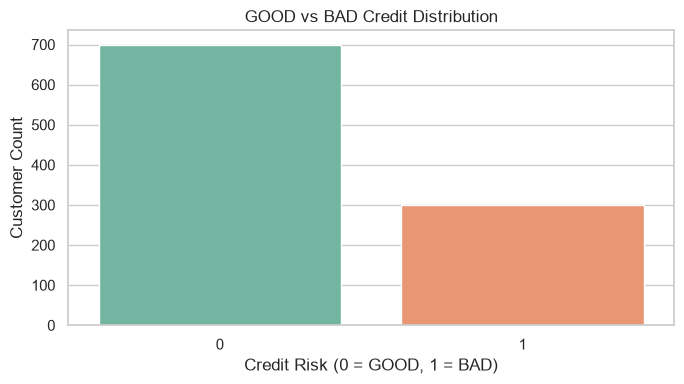


3. NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max,Skewness,Missing_Values
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95,0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53,0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02,0
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27,0
people_liable,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91,0



4. CATEGORICAL FEATURE SUMMARY


,Unique_Categories,Missing_Values,Most_Frequent_Category
checking_account,4,0,A14
credit_history,5,0,A32
purpose,10,0,A43
savings_account,5,0,A61
employment_duration,5,0,A73
personal_status_sex,4,0,A93
other_debtors,3,0,A101
property,4,0,A123
other_installment_plans,3,0,A143
housing,3,0,A152



5. SPECIAL CATEGORY SUMMARY

Feature: savings_account
Category: A65
Frequency: 183
Percentage: 18.30%
Interpretation: Retain as a valid category.

Feature: property
Category: A124
Frequency: 154
Percentage: 15.40%
Interpretation: Retain as a valid category.

6. MISSING VALUE SUMMARY
No missing values detected.

7. NUMERICAL FEATURES VS CREDIT RISK


,GOOD_Mean,BAD_Mean,Difference
credit_amount,2985.46,3938.13,952.67
installment_rate,2.92,3.10,0.18
age,36.22,33.96,-2.26
existing_credits,1.42,1.37,-0.06
people_liable,1.16,1.15,-0.00


... (29 outputs left out)

,Frequency
foreign_worker,
A201,963
A202,37



10. PREPROCESSING RECOMMENDATIONS


,Area,Recommendation
0,Missing Values,Check missing-value patterns and apply suitabl...
1,Duplicate Records,Investigate duplicates before deciding whether...
2,Numerical Features,Consider StandardScaler or RobustScaler where ...
3,Categorical Features,Use One-Hot Encoding for nominal categories.
4,Ordinal Features,Use ordinal encoding only when a meaningful or...
5,A65 and A124,Preserve as valid categories; do not convert t...
6,Outliers,Investigate unusual values before deciding on ...
7,Target Variable,Preserve BAD=1 and GOOD=0 consistently.
8,Data Splitting,Use stratified train-test splitting.
9,Data Leakage,"Fit imputers, scalers and encoders on training..."



11. FINAL EDA FINDINGS
1. The German Credit dataset contains customer credit information.
2. The target variable distinguishes GOOD and BAD credit customers.
3. Numerical features describe credit amount, duration, age
   and other customer financial characteristics.
4. Categorical features describe account status, credit history,
   savings, employment, housing and other characteristics.
5. A65 and A124 are valid categorical codes.
6. Numerical distributions and outliers should be considered
   during preprocessing.
7. Category-wise BAD credit rates reveal historical risk patterns.
8. Protected attributes require careful fairness evaluation.
9. Preprocessing should be performed using training data only.
10. Model evaluation should consider class imbalance and
    multiple performance metrics.

12. FINAL VALIDATION
Dataset Overview: Completed
Target Distribution: Completed
Numerical Summary: Completed
Categorical Summary: Completed
Special Category Audit: Completed
Missing Value Summar

In [7]:

# ============================================================
# SECTION 7: SUMMARY OF EDA FINDINGS
# & PREPROCESSING RECOMMENDATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# 1. DATASET OVERVIEW

print("\n1. DATASET OVERVIEW")
print("=" * 65)

print("Dataset Shape:", df.shape)
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Duplicate Rows:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())

dataset_summary = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100,
    "Unique_Values": df.nunique()
})

display(dataset_summary.round(2))


# 2. TARGET VARIABLE SUMMARY

print("\n2. TARGET VARIABLE SUMMARY")
print("=" * 65)

target_col = "credit_risk"

assert target_col in df.columns, \
    "credit_risk column not found."

target_counts = df[target_col].value_counts().sort_index()

target_percentages = (
    df[target_col].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Customer_Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary.round(2))

print("\nGOOD Customers:", (df[target_col] == 0).sum())
print("BAD Customers:", (df[target_col] == 1).sum())

if set(df[target_col].dropna().unique()).issubset({0, 1}):

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=target_col,
        hue=target_col,
        order=[0, 1],
        palette="Set2",
        legend=False
    )

    plt.title("GOOD vs BAD Credit Distribution")
    plt.xlabel("Credit Risk (0 = GOOD, 1 = BAD)")
    plt.ylabel("Customer Count")
    plt.tight_layout()
    plt.show()


# 3. NUMERICAL FEATURE SUMMARY

print("\n3. NUMERICAL FEATURE SUMMARY")
print("=" * 65)

numerical_cols = [
    col for col in numerical_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

if numerical_cols:

    numerical_summary = df[numerical_cols].describe().T

    numerical_summary["Skewness"] = (
        df[numerical_cols].skew()
    )

    numerical_summary["Missing_Values"] = (
        df[numerical_cols].isnull().sum()
    )

    display(numerical_summary.round(2))

else:
    print("No numerical features available.")


# 4. CATEGORICAL FEATURE SUMMARY

print("\n4. CATEGORICAL FEATURE SUMMARY")
print("=" * 65)

categorical_cols = [
    col for col in categorical_cols
    if col in df.columns
]

if categorical_cols:

    categorical_summary = pd.DataFrame({
        "Unique_Categories": df[categorical_cols].nunique(),
        "Missing_Values": df[categorical_cols].isnull().sum(),
        "Most_Frequent_Category": [
            df[col].mode().iloc[0]
            if not df[col].mode().empty
            else np.nan
            for col in categorical_cols
        ]
    })

    display(categorical_summary)

else:
    print("No categorical features available.")


# 5. SPECIAL CATEGORY SUMMARY: A65 AND A124

print("\n5. SPECIAL CATEGORY SUMMARY")
print("=" * 65)

special_categories = {
    "savings_account": "A65",
    "property": "A124"
}

for col, category in special_categories.items():

    if col in df.columns:

        count = (df[col] == category).sum()

        percentage = (
            count / len(df) * 100
        )

        print(f"\nFeature: {col}")
        print(f"Category: {category}")
        print(f"Frequency: {count}")
        print(f"Percentage: {percentage:.2f}%")

        print("Interpretation: Retain as a valid category.")


# 6. MISSING VALUE SUMMARY

print("\n6. MISSING VALUE SUMMARY")
print("=" * 65)

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

if not missing_summary.empty:

    display(missing_summary.round(2))

else:

    print("No missing values detected.")


# 7. CREDIT RISK FINDINGS BY NUMERICAL FEATURES

print("\n7. NUMERICAL FEATURES VS CREDIT RISK")
print("=" * 65)

if numerical_cols:

    numerical_risk_summary = (
        df.groupby(target_col)[numerical_cols]
        .mean()
        .T
    )

    numerical_risk_summary.columns = [
        "GOOD_Mean",
        "BAD_Mean"
    ]

    numerical_risk_summary["Difference"] = (
        numerical_risk_summary["BAD_Mean"]
        - numerical_risk_summary["GOOD_Mean"]
    )

    display(numerical_risk_summary.round(2))


# 8. CREDIT RISK FINDINGS BY CATEGORICAL FEATURES

print("\n8. CATEGORICAL FEATURES VS CREDIT RISK")
print("=" * 65)

for col in categorical_cols:

    risk_summary = (
        df.groupby(col, observed=True)[target_col]
        .agg(["count", "mean"])
    )

    risk_summary.columns = [
        "Customer_Count",
        "BAD_Credit_Rate"
    ]

    risk_summary["BAD_Credit_Rate"] *= 100

    print(f"\nFeature: {col}")

    display(risk_summary.round(2))


# 9. PROTECTED ATTRIBUTE SUMMARY

print("\n9. PROTECTED ATTRIBUTE AUDIT SUMMARY")
print("=" * 65)

protected_cols = [
    col for col in [
        "personal_status_sex",
        "age",
        "foreign_worker"
    ]
    if col in df.columns
]

for col in protected_cols:

    print(f"\nFeature: {col}")

    print("Unique Categories / Values:",
          df[col].nunique())

    if col == "age":

        print("Minimum Age:", df[col].min())
        print("Maximum Age:", df[col].max())
        print("Average Age:", round(df[col].mean(), 2))

    else:

        display(
            df[col].value_counts(dropna=False).to_frame(
                name="Frequency"
            )
        )


# 10. PREPROCESSING RECOMMENDATIONS

print("\n10. PREPROCESSING RECOMMENDATIONS")
print("=" * 65)

recommendations = [
    [
        "Missing Values",
        "Check missing-value patterns and apply suitable imputation."
    ],
    [
        "Duplicate Records",
        "Investigate duplicates before deciding whether to remove them."
    ],
    [
        "Numerical Features",
        "Consider StandardScaler or RobustScaler where appropriate."
    ],
    [
        "Categorical Features",
        "Use One-Hot Encoding for nominal categories."
    ],
    [
        "Ordinal Features",
        "Use ordinal encoding only when a meaningful order exists."
    ],
    [
        "A65 and A124",
        "Preserve as valid categories; do not convert to NaN."
    ],
    [
        "Outliers",
        "Investigate unusual values before deciding on treatment."
    ],
    [
        "Target Variable",
        "Preserve BAD=1 and GOOD=0 consistently."
    ],
    [
        "Data Splitting",
        "Use stratified train-test splitting."
    ],
    [
        "Data Leakage",
        "Fit imputers, scalers and encoders on training data only."
    ],
    [
        "Class Imbalance",
        "Evaluate class weights and suitable performance metrics."
    ],
    [
        "Protected Attributes",
        "Evaluate fairness and applicable legal requirements."
    ]
]

recommendation_df = pd.DataFrame(
    recommendations,
    columns=["Area", "Recommendation"]
)

display(recommendation_df)


# 11. FINAL EDA FINDINGS

print("\n11. FINAL EDA FINDINGS")
print("=" * 65)

print("1. The German Credit dataset contains customer credit information.")

print("2. The target variable distinguishes GOOD and BAD credit customers.")

print("3. Numerical features describe credit amount, duration, age")
print("   and other customer financial characteristics.")

print("4. Categorical features describe account status, credit history,")
print("   savings, employment, housing and other characteristics.")

print("5. A65 and A124 are valid categorical codes.")

print("6. Numerical distributions and outliers should be considered")
print("   during preprocessing.")

print("7. Category-wise BAD credit rates reveal historical risk patterns.")

print("8. Protected attributes require careful fairness evaluation.")

print("9. Preprocessing should be performed using training data only.")

print("10. Model evaluation should consider class imbalance and")
print("    multiple performance metrics.")


# 12. FINAL VALIDATION

print("\n12. FINAL VALIDATION")
print("=" * 65)

assert target_col in df.columns
assert df[target_col].notna().all()
assert set(df[target_col].unique()).issubset({0, 1})

assert all(col in df.columns for col in numerical_cols)
assert all(col in df.columns for col in categorical_cols)

print("Dataset Overview: Completed")
print("Target Distribution: Completed")
print("Numerical Summary: Completed")
print("Categorical Summary: Completed")
print("Special Category Audit: Completed")
print("Missing Value Summary: Completed")
print("Credit Risk Findings: Completed")
print("Protected Attribute Summary: Completed")
print("Preprocessing Recommendations: Completed")

print("\n================================================")
print("SECTION 7 COMPLETED SUCCESSFULLY")
print("================================================")
